<a href="https://colab.research.google.com/github/CheredlaJasvina/DSA0302-NLP/blob/main/DSA0302_AT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task 1

Total utterances: 30

DATASET SPLIT
Training utterances: 24
Development utterances: 3
Test utterances: 3

WORD COUNTING RESULTS
Total Tokens: 158
Unique Types: 55
Unique Lemmas: 52
Unique Word Forms: 55

TOKENIZATION COMPARISON
Method 1 - Lowercase vocabulary: 58
Method 2 - Preserve case vocabulary: 60

VOCABULARY AND UNK ANALYSIS

Threshold: 1
Vocabulary Size: 55
Tokens mapped to UNK: 0
UNK Percentage: 0.0 %

Threshold: 2
Vocabulary Size: 29
Tokens mapped to UNK: 26
UNK Percentage: 16.46 %

Threshold: 3
Vocabulary Size: 22
Tokens mapped to UNK: 40
UNK Percentage: 25.32 %

Threshold: 5
Vocabulary Size: 8
Tokens mapped to UNK: 84
UNK Percentage: 53.16 %

DEVELOPMENT SET OOV ANALYSIS
Development Tokens: 21
OOV Tokens: 2
OOV Rate: 9.52 %


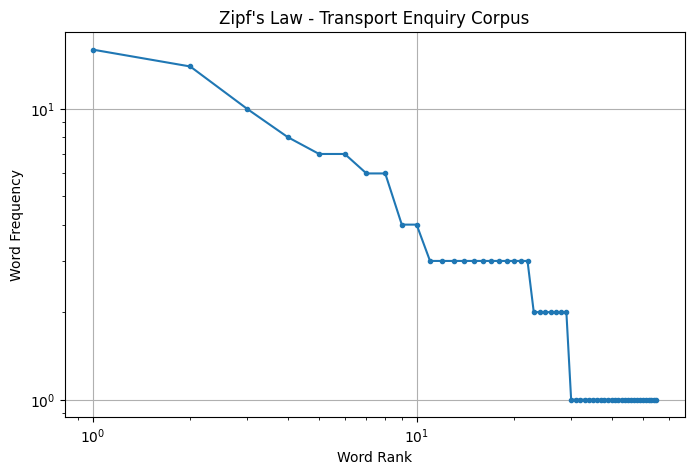


TOP 10 MOST FREQUENT WORDS
to : 16
the : 14
train : 10
ticket : 8
is : 7
i : 7
bus : 6
a : 6
me : 4
chennai : 4

FINAL SUMMARY
Total Corpus Utterances: 30
Training Tokens: 158
Vocabulary Size: 55
Development OOV Rate: 9.52 %
Task 1 Completed Successfully!


In [ ]:

# TASK 1: COUNTING WORDS AND BUILDING THE VOCABULARY

import re
import random
import nltk
import matplotlib.pyplot as plt

from collections import Counter
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

# ------------------------------------------------
# 1. CREATE TRANSPORT ENQUIRY CORPUS
# ------------------------------------------------

utterances = [
    "I want two tickets to Vellore",
    "What is the bus timing to Chennai",
    "Book a train ticket to Madurai",
    "When will the next bus arrive",
    "Tell me the ticket fare to Bangalore",
    "I want to cancel my bus ticket",
    "Is there a train from Chennai to Vellore",
    "What is the departure time of the bus",
    "I need a return ticket to Hyderabad",
    "Show me the available train timings",
    "How much is the fare to Madurai",
    "I want to book three bus tickets",
    "When does the first train leave",
    "Is the bus available today",
    "Tell me the arrival time of the train",
    "I need two tickets to Chennai",
    "What is the distance to Vellore",
    "Can I get a refund for my ticket",
    "Show the bus route to Bangalore",
    "When is the next train to Hyderabad",
    "Book a bus ticket from Chennai",
    "What time does the train arrive",
    "I need a ticket to Coimbatore",
    "Is there a bus to Tirupati",
    "Tell me the train fare to Vellore",
    "I want to book a return ticket",
    "When is the last bus to Madurai",
    "Can I change my train ticket",
    "Show available buses to Chennai",
    "How much does a train ticket cost"
]

print("Total utterances:", len(utterances))

# ------------------------------------------------
# 2. TOKENIZATION AND NORMALIZATION
# ------------------------------------------------

fillers = {"uh", "um", "erm", "hmm"}

def tokenize(sentence):
    sentence = sentence.lower()

    # Replace standalone numbers with NUM
    sentence = re.sub(r"\b\d+\b", " NUM ", sentence)

    # Preserve clock times as one token
    words = re.findall(
        r"\d{1,2}:\d{2}|[a-z]+|NUM",
        sentence
    )

    # Remove disfluencies
    words = [word for word in words if word not in fillers]

    return words

tokenized_data = [tokenize(s) for s in utterances]

# Add utterance boundary markers
data_with_boundaries = [
    ["<s>"] + sentence + ["</s>"]
    for sentence in tokenized_data
]

# ------------------------------------------------
# 3. SPLIT DATA INTO TRAIN, DEVELOPMENT AND TEST
# ------------------------------------------------

random.seed(42)

indices = list(range(len(tokenized_data)))
random.shuffle(indices)

n = len(indices)

train_end = int(0.80 * n)
dev_end = int(0.90 * n)

train = [tokenized_data[i] for i in indices[:train_end]]
dev = [tokenized_data[i] for i in indices[train_end:dev_end]]
test = [tokenized_data[i] for i in indices[dev_end:]]

print("\nDATASET SPLIT")
print("Training utterances:", len(train))
print("Development utterances:", len(dev))
print("Test utterances:", len(test))

# ------------------------------------------------
# 4. COUNT TOKENS, TYPES, LEMMAS AND WORD FORMS
# ------------------------------------------------

train_tokens = [word for sentence in train for word in sentence]

total_tokens = len(train_tokens)

# Unique types
unique_types = set(train_tokens)
type_count = len(unique_types)

# Unique word forms
word_forms = set(train_tokens)
word_form_count = len(word_forms)

# Lemmatization
lemmatizer = WordNetLemmatizer()

lemmas = [
    lemmatizer.lemmatize(word)
    for word in train_tokens
]

unique_lemmas = set(lemmas)
lemma_count = len(unique_lemmas)

print("\nWORD COUNTING RESULTS")
print("Total Tokens:", total_tokens)
print("Unique Types:", type_count)
print("Unique Lemmas:", lemma_count)
print("Unique Word Forms:", word_form_count)

# ------------------------------------------------
# 5. TOKENIZATION DECISION COMPARISON
# ------------------------------------------------

method1 = set(
    word for sentence in utterances
    for word in re.findall(r"[a-z]+", sentence.lower())
)

method2 = set(
    word for sentence in utterances
    for word in re.findall(r"[A-Za-z]+", sentence)
)

print("\nTOKENIZATION COMPARISON")
print("Method 1 - Lowercase vocabulary:", len(method1))
print("Method 2 - Preserve case vocabulary:", len(method2))

# ------------------------------------------------
# 6. BUILD VOCABULARY AND MAP RARE WORDS TO UNK
# ------------------------------------------------

frequency = Counter(train_tokens)

print("\nVOCABULARY AND UNK ANALYSIS")

for threshold in [1, 2, 3, 5]:

    vocabulary = {
        word for word, count in frequency.items()
        if count >= threshold
    }

    unk_tokens = sum(
        count for word, count in frequency.items()
        if count < threshold
    )

    unk_percentage = (
        unk_tokens / total_tokens * 100
        if total_tokens else 0
    )

    print("\nThreshold:", threshold)
    print("Vocabulary Size:", len(vocabulary))
    print("Tokens mapped to UNK:", unk_tokens)
    print("UNK Percentage:", round(unk_percentage, 2), "%")

# ------------------------------------------------
# 7. DEVELOPMENT SET OOV RATE
# ------------------------------------------------

train_vocabulary = set(train_tokens)

dev_tokens = [
    word for sentence in dev
    for word in sentence
]

oov_tokens = [
    word for word in dev_tokens
    if word not in train_vocabulary
]

oov_rate = (
    len(oov_tokens) / len(dev_tokens) * 100
    if dev_tokens else 0
)

print("\nDEVELOPMENT SET OOV ANALYSIS")
print("Development Tokens:", len(dev_tokens))
print("OOV Tokens:", len(oov_tokens))
print("OOV Rate:", round(oov_rate, 2), "%")

# ------------------------------------------------
# 8. ZIPF'S LAW GRAPH
# ------------------------------------------------

sorted_frequency = sorted(
    frequency.values(),
    reverse=True
)

ranks = range(1, len(sorted_frequency) + 1)

plt.figure(figsize=(8, 5))
plt.loglog(ranks, sorted_frequency, marker=".")
plt.xlabel("Word Rank")
plt.ylabel("Word Frequency")
plt.title("Zipf's Law - Transport Enquiry Corpus")
plt.grid(True)
plt.show()

# ------------------------------------------------
# 9. DISPLAY TOP 10 FREQUENT WORDS
# ------------------------------------------------

print("\nTOP 10 MOST FREQUENT WORDS")

for word, count in frequency.most_common(10):
    print(word, ":", count)

# ------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------

print("\nFINAL SUMMARY")
print("Total Corpus Utterances:", len(utterances))
print("Training Tokens:", total_tokens)
print("Vocabulary Size:", type_count)
print("Development OOV Rate:", round(oov_rate, 2), "%")
print("Task 1 Completed Successfully!")


Task 2

In [ ]:

# TASK 2: UNSMOOTHED N-GRAM MODELS

import re
import random
import math
import matplotlib.pyplot as plt

from collections import Counter, defaultdict

random.seed(42)

# ------------------------------------------------
# 1. CREATE TRANSPORT ENQUIRY CORPUS
# ------------------------------------------------

utterances = [
    "I want two tickets to Vellore",
    "What is the bus timing to Chennai",
    "Book a train ticket to Madurai",
    "When will the next bus arrive",
    "Tell me the ticket fare to Bangalore",
    "I want to cancel my bus ticket",
    "Is there a train from Chennai to Vellore",
    "What is the departure time of the bus",
    "I need a return ticket to Hyderabad",
    "Show me the available train timings",
    "How much is the fare to Madurai",
    "I want to book three bus tickets",
    "When does the first train leave",
    "Is the bus available today",
    "Tell me the arrival time of the train",
    "I need two tickets to Chennai",
    "What is the distance to Vellore",
    "Can I get a refund for my ticket",
    "Show the bus route to Bangalore",
    "When is the next train to Hyderabad",
    "Book a bus ticket from Chennai",
    "What time does the train arrive",
    "I need a ticket to Coimbatore",
    "Is there a bus to Tirupati",
    "Tell me the train fare to Vellore",
    "I want to book a return ticket",
    "When is the last bus to Madurai",
    "Can I change my train ticket",
    "Show available buses to Chennai",
    "How much does a train ticket cost"
]

# ------------------------------------------------
# 2. TOKENIZATION
# ------------------------------------------------

def tokenize(sentence):
    sentence = sentence.lower()
    return re.findall(r"[a-z]+|\d+", sentence)

sentences = [tokenize(s) for s in utterances]

# Add sentence boundary markers
sentences = [
    ["<s>"] + sentence + ["</s>"]
    for sentence in sentences
]

# ------------------------------------------------
# 3. SPLIT DATA: 80% TRAIN, 10% DEV, 10% TEST
# ------------------------------------------------

indices = list(range(len(sentences)))
random.shuffle(indices)

n = len(indices)

train_end = int(0.80 * n)
dev_end = int(0.90 * n)

train = [sentences[i] for i in indices[:train_end]]
dev = [sentences[i] for i in indices[train_end:dev_end]]
test = [sentences[i] for i in indices[dev_end:]]

print("Training sentences:", len(train))
print("Development sentences:", len(dev))
print("Test sentences:", len(test))

# ------------------------------------------------
# 4. BUILD UNIGRAM, BIGRAM AND TRIGRAM COUNTS
# ------------------------------------------------

train_tokens = [
    word for sentence in train for word in sentence
]

unigram_counts = Counter(train_tokens)

bigram_counts = Counter()
trigram_counts = Counter()

for sentence in train:
    for i in range(len(sentence) - 1):
        bigram_counts[(sentence[i], sentence[i+1])] += 1

    for i in range(len(sentence) - 2):
        trigram_counts[
            (sentence[i], sentence[i+1], sentence[i+2])
        ] += 1

bigram_context_counts = Counter()
trigram_context_counts = Counter()

for (w1, w2), count in bigram_counts.items():
    bigram_context_counts[w1] += count

for (w1, w2, w3), count in trigram_counts.items():
    trigram_context_counts[(w1, w2)] += count

vocabulary = set(train_tokens)
V = len(vocabulary)

print("\nVOCABULARY SIZE:", V)

# ------------------------------------------------
# 5. MLE PROBABILITY FUNCTIONS
# ------------------------------------------------

def unigram_probability(word):
    return unigram_counts[word] / len(train_tokens)

def bigram_probability(w1, w2):
    if bigram_context_counts[w1] == 0:
        return 0
    return (
        bigram_counts[(w1, w2)] /
        bigram_context_counts[w1]
    )

def trigram_probability(w1, w2, w3):
    context = (w1, w2)

    if trigram_context_counts[context] == 0:
        return 0

    return (
        trigram_counts[(w1, w2, w3)] /
        trigram_context_counts[context]
    )

# ------------------------------------------------
# 6. SENTENCE PROBABILITY
# ------------------------------------------------

def sentence_probabilities(sentence):

    words = ["<s>"] + tokenize(sentence) + ["</s>"]

    # Unigram probability
    p1 = 1.0

    for word in words[1:]:
        p1 *= unigram_probability(word)

    # Bigram probability
    p2 = 1.0

    for i in range(1, len(words)):
        p2 *= bigram_probability(words[i-1], words[i])

    # Trigram probability
    padded = ["<s>", "<s>"] + tokenize(sentence) + ["</s>"]
    p3 = 1.0

    for i in range(2, len(padded)):
        p3 *= trigram_probability(
            padded[i-2], padded[i-1], padded[i]
        )

    return p1, p2, p3

# ------------------------------------------------
# 7. CALCULATE THREE UTTERANCE PROBABILITIES
# ------------------------------------------------

test_sentences = [
    "I want two tickets to Vellore",
    "What is the bus timing to Chennai",
    "Book a train ticket to Madurai"
]

print("\nSENTENCE PROBABILITIES")

for sentence in test_sentences:
    p1, p2, p3 = sentence_probabilities(sentence)

    print("\nSentence:", sentence)
    print("Unigram Probability:", p1)
    print("Bigram Probability:", p2)
    print("Trigram Probability:", p3)

# ------------------------------------------------
# 8. FIND A ZERO-PROBABILITY BIGRAM EXAMPLE
# ------------------------------------------------

candidate_sentences = [
    "I want a bus to Vellore",
    "Please book a train to Chennai",
    "The bus is going to Madurai",
    "Can I get a ticket to Hyderabad",
    "I need a train ticket to Bangalore"
]

print("\nZERO PROBABILITY EXAMPLE")

found = False

for sentence in candidate_sentences:
    words = ["<s>"] + tokenize(sentence) + ["</s>"]

    for i in range(1, len(words)):
        pair = (words[i-1], words[i])

        if bigram_counts[pair] == 0:
            print("Sentence:", sentence)
            print("Unseen Bigram:", pair)
            print("Bigram Probability:", 0)
            found = True
            break

    if found:
        break

if not found:
    print("No zero-probability example found in candidate list.")

# ------------------------------------------------
# 9. MODEL SPARSITY
# ------------------------------------------------

# Possible bigrams and trigrams based on training vocabulary
possible_bigrams = V ** 2
possible_trigrams = V ** 3

observed_bigrams = len(bigram_counts)
observed_trigrams = len(trigram_counts)

bigram_sparsity = (
    observed_bigrams / possible_bigrams * 100
)

trigram_sparsity = (
    observed_trigrams / possible_trigrams * 100
)

print("\nTRAINING MODEL SPARSITY")
print("Observed bigrams:", observed_bigrams)
print("Possible bigrams:", possible_bigrams)
print("Observed bigram percentage:", round(bigram_sparsity, 4), "%")

print("\nObserved trigrams:", observed_trigrams)
print("Possible trigrams:", possible_trigrams)
print("Observed trigram percentage:", round(trigram_sparsity, 6), "%")

# Development unseen n-grams
dev_bigrams = []
dev_trigrams = []

for sentence in dev:
    for i in range(len(sentence)-1):
        dev_bigrams.append((sentence[i], sentence[i+1]))

    for i in range(len(sentence)-2):
        dev_trigrams.append(
            (sentence[i], sentence[i+1], sentence[i+2])
        )

unseen_dev_bigrams = sum(
    1 for bg in dev_bigrams if bg not in bigram_counts
)

unseen_dev_trigrams = sum(
    1 for tg in dev_trigrams if tg not in trigram_counts
)

print("\nDEVELOPMENT SET SPARSITY")
print(
    "Unseen bigram percentage:",
    round(unseen_dev_bigrams / len(dev_bigrams) * 100, 2)
    if dev_bigrams else 0,
    "%"
)

print(
    "Unseen trigram percentage:",
    round(unseen_dev_trigrams / len(dev_trigrams) * 100, 2)
    if dev_trigrams else 0,
    "%"
)

# ------------------------------------------------
# 10. GENERATE SENTENCES FROM N-GRAM MODELS
# ------------------------------------------------

def weighted_choice(counter):
    words = list(counter.keys())
    weights = list(counter.values())

    return random.choices(words, weights=weights, k=1)[0]

# Unigram generation
def generate_unigram(max_length=12):
    result = []

    for _ in range(max_length):
        candidates = {
            word: count
            for word, count in unigram_counts.items()
            if word not in ("<s>", "</s>")
        }

        word = weighted_choice(candidates)
        result.append(word)

    return " ".join(result)

# Bigram generation
bigram_next = defaultdict(Counter)

for (w1, w2), count in bigram_counts.items():
    bigram_next[w1][w2] += count

def generate_bigram(max_length=12):
    result = []
    current = "<s>"

    for _ in range(max_length):
        candidates = bigram_next[current]

        if not candidates:
            break

        word = weighted_choice(candidates)

        if word == "</s>":
            break

        result.append(word)
        current = word

    return " ".join(result)

# Trigram generation
trigram_next = defaultdict(Counter)

for (w1, w2, w3), count in trigram_counts.items():
    trigram_next[(w1, w2)][w3] += count

def generate_trigram(max_length=12):
    result = []
    context = ("<s>", "<s>")

    for _ in range(max_length):
        candidates = trigram_next[context]

        if not candidates:
            break

        word = weighted_choice(candidates)

        if word == "</s>":
            break

        result.append(word)
        context = (context[1], word)

    return " ".join(result)

print("\n10 UNIGRAM GENERATED SENTENCES")

for i in range(10):
    print(i+1, generate_unigram())

print("\n10 BIGRAM GENERATED SENTENCES")

for i in range(10):
    print(i+1, generate_bigram())

print("\n10 TRIGRAM GENERATED SENTENCES")

for i in range(10):
    print(i+1, generate_trigram())

print("\nTASK 2 COMPLETED")


Training sentences: 24
Development sentences: 3
Test sentences: 3

VOCABULARY SIZE: 57

SENTENCE PROBABILITIES

Sentence: I want two tickets to Vellore
Unigram Probability: 3.0734859128778763e-12
Bigram Probability: 0.0
Trigram Probability: 0.0

Sentence: What is the bus timing to Chennai
Unigram Probability: 8.355107335978693e-13
Bigram Probability: 0.0003587372448979591
Trigram Probability: 0.0

Sentence: Book a train ticket to Madurai
Unigram Probability: 1.0537665987009864e-10
Bigram Probability: 0.0001953125
Trigram Probability: 0.0

ZERO PROBABILITY EXAMPLE
Sentence: I want a bus to Vellore
Unseen Bigram: ('want', 'a')
Bigram Probability: 0

TRAINING MODEL SPARSITY
Observed bigrams: 117
Possible bigrams: 3249
Observed bigram percentage: 3.6011 %

Observed trigrams: 133
Possible trigrams: 185193
Observed trigram percentage: 0.071817 %

DEVELOPMENT SET SPARSITY
Unseen bigram percentage: 25.0 %
Unseen trigram percentage: 57.14 %

10 UNIGRAM GENERATED SENTENCES
1 a book when book vel

Task 3

Training sentences: 24
Development sentences: 3

Vocabulary size: 57
Total bigram tokens: 182
Observed bigram types: 117

Selected context: <s>
Context count: 24

ADD-ONE AND ADD-K RESULTS
Context: <s>
Next Word       Original     Add-One Count   Add-One Prob    Add-k Prob     
book            1            2               0.024691        0.028571       
can             2            3               0.037037        0.047619       
how             2            3               0.037037        0.047619       
i               5            6               0.074074        0.104762       
is              2            3               0.037037        0.047619       
show            3            4               0.049383        0.066667       
tell            3            4               0.049383        0.066667       
what            3            4               0.049383        0.066667       
when            3            4               0.049383        0.066667       

Unseen bigram: <s> </s>
Add

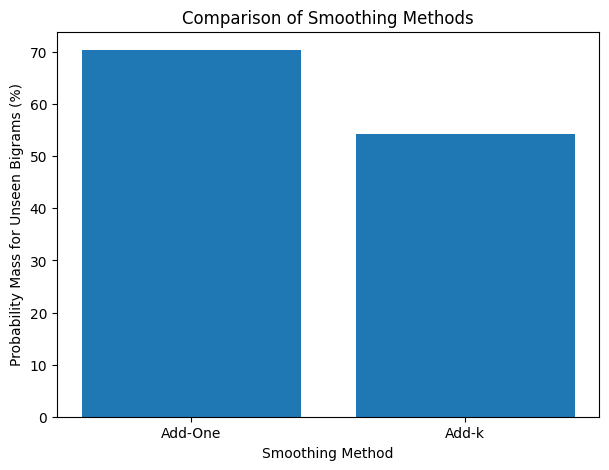


TASK 3 COMPLETED SUCCESSFULLY


In [ ]:

# TASK 3: SMOOTHING AND DISCOUNTING

import re
import random
from collections import Counter, defaultdict
import matplotlib.pyplot as plt

random.seed(42)

# ------------------------------------------------
# 1. TRANSPORT ENQUIRY CORPUS
# ------------------------------------------------

utterances = [
    "I want two tickets to Vellore",
    "What is the bus timing to Chennai",
    "Book a train ticket to Madurai",
    "When will the next bus arrive",
    "Tell me the ticket fare to Bangalore",
    "I want to cancel my bus ticket",
    "Is there a train from Chennai to Vellore",
    "What is the departure time of the bus",
    "I need a return ticket to Hyderabad",
    "Show me the available train timings",
    "How much is the fare to Madurai",
    "I want to book three bus tickets",
    "When does the first train leave",
    "Is the bus available today",
    "Tell me the arrival time of the train",
    "I need two tickets to Chennai",
    "What is the distance to Vellore",
    "Can I get a refund for my ticket",
    "Show the bus route to Bangalore",
    "When is the next train to Hyderabad",
    "Book a bus ticket from Chennai",
    "What time does the train arrive",
    "I need a ticket to Coimbatore",
    "Is there a bus to Tirupati",
    "Tell me the train fare to Vellore",
    "I want to book a return ticket",
    "When is the last bus to Madurai",
    "Can I change my train ticket",
    "Show available buses to Chennai",
    "How much does a train ticket cost"
]

# ------------------------------------------------
# 2. TOKENIZATION
# ------------------------------------------------

def tokenize(sentence):
    sentence = sentence.lower()
    return re.findall(r"[a-z]+|\d+", sentence)

sentences = [
    ["<s>"] + tokenize(s) + ["</s>"]
    for s in utterances
]

# ------------------------------------------------
# 3. TRAINING AND DEVELOPMENT SPLIT
# ------------------------------------------------

indices = list(range(len(sentences)))
random.shuffle(indices)

n = len(indices)

train_end = int(0.80 * n)
dev_end = int(0.90 * n)

train = [sentences[i] for i in indices[:train_end]]
dev = [sentences[i] for i in indices[train_end:dev_end]]

print("Training sentences:", len(train))
print("Development sentences:", len(dev))

# ------------------------------------------------
# 4. BUILD BIGRAM COUNTS
# ------------------------------------------------

bigram_counts = Counter()
context_counts = Counter()

for sentence in train:
    for i in range(len(sentence) - 1):
        w1 = sentence[i]
        w2 = sentence[i + 1]

        bigram_counts[(w1, w2)] += 1
        context_counts[w1] += 1

vocabulary = set(
    word for sentence in train for word in sentence
)

V = len(vocabulary)
N = sum(bigram_counts.values())

print("\nVocabulary size:", V)
print("Total bigram tokens:", N)
print("Observed bigram types:", len(bigram_counts))

# ------------------------------------------------
# 5. SELECT A CONTEXT FOR COMPARISON
# ------------------------------------------------

context = max(context_counts, key=context_counts.get)

C = context_counts[context]

print("\nSelected context:", context)
print("Context count:", C)

# ------------------------------------------------
# 6. ADD-ONE AND ADD-K SMOOTHING
# ------------------------------------------------

k = 0.5

continuations = [
    word for (w1, word) in bigram_counts
    if w1 == context
]

print("\nADD-ONE AND ADD-K RESULTS")
print("Context:", context)

print(
    "{:<15} {:<12} {:<15} {:<15} {:<15}".format(
        "Next Word", "Original", "Add-One Count",
        "Add-One Prob", "Add-k Prob"
    )
)

for word in sorted(continuations):
    count = bigram_counts[(context, word)]

    add_one_count = count + 1

    add_one_prob = (
        add_one_count / (C + V)
    )

    add_k_prob = (
        (count + k) / (C + k * V)
    )

    print(
        "{:<15} {:<12} {:<15} {:<15.6f} {:<15.6f}".format(
            word, count, add_one_count,
            add_one_prob, add_k_prob
        )
    )

# Display an unseen continuation
unseen_word = next(
    (word for word in sorted(vocabulary)
     if (context, word) not in bigram_counts),
    None
)

if unseen_word is not None:
    print("\nUnseen bigram:", context, unseen_word)

    print(
        "Add-One probability:",
        1 / (C + V)
    )

    print(
        "Add-k probability:",
        k / (C + k * V)
    )

# ------------------------------------------------
# 7. PROBABILITY MASS REMOVED FROM SEEN BIGRAMS
# ------------------------------------------------

add_one_unseen_mass = V / (C + V)

add_k_unseen_mass = (k * V) / (C + k * V)

add_one_seen_mass = C / (C + V)

add_k_seen_mass = C / (C + k * V)

print("\nPROBABILITY MASS ANALYSIS")

print("Original seen probability mass: 1.0")

print(
    "Add-One mass assigned to unseen bigrams:",
    round(add_one_unseen_mass, 6)
)

print(
    "Add-One mass remaining for seen bigrams:",
    round(add_one_seen_mass, 6)
)

print(
    "Add-k mass assigned to unseen bigrams:",
    round(add_k_unseen_mass, 6)
)

print(
    "Add-k mass remaining for seen bigrams:",
    round(add_k_seen_mass, 6)
)

# ------------------------------------------------
# 8. ADD-ONE SEVERITY
# ------------------------------------------------

print("\nADD-ONE SMOOTHING SEVERITY")

print("Context:", context)
print("Context frequency:", C)
print("Vocabulary size:", V)

print(
    "Probability mass removed from seen bigrams:",
    round(add_one_unseen_mass * 100, 2), "%"
)

print(
    "Explanation: A larger vocabulary increases the "
    "probability mass assigned to unseen bigrams."
)

# ------------------------------------------------
# 9. GOOD-TURING FREQUENCY OF FREQUENCIES
# ------------------------------------------------

Nr = Counter(bigram_counts.values())

print("\nGOOD-TURING FREQUENCY OF FREQUENCIES")

print("{:<15} {:<15}".format("Frequency (r)", "N_r"))

for r in sorted(Nr):
    print("{:<15} {:<15}".format(r, Nr[r]))

# ------------------------------------------------
# 10. GOOD-TURING REVISED COUNTS
# ------------------------------------------------

print("\nGOOD-TURING REVISED COUNTS")

print(
    "{:<15} {:<15} {:<15} {:<15}".format(
        "Original c", "N_c", "N_c+1", "Revised c*"
    )
)

for c in sorted(Nr):
    Nc = Nr[c]
    Nc1 = Nr.get(c + 1, 0)

    if Nc1 > 0:
        revised = (c + 1) * Nc1 / Nc
    else:
        # Raw-count fallback for the high-frequency tail
        revised = c

    print(
        "{:<15} {:<15} {:<15} {:<15.4f}".format(
            c, Nc, Nc1, revised
        )
    )

# ------------------------------------------------
# 11. GOOD-TURING UNSEEN BIGRAM PROBABILITY
# ------------------------------------------------

N1 = Nr.get(1, 0)

possible_bigrams = V ** 2
observed_bigrams = len(bigram_counts)

N0 = possible_bigrams - observed_bigrams

P0 = N1 / N if N > 0 else 0

print("\nGOOD-TURING UNSEEN BIGRAM ANALYSIS")

print("N1 (bigram types occurring once):", N1)
print("Total bigram tokens:", N)
print("Possible bigram types:", possible_bigrams)
print("Observed bigram types:", observed_bigrams)
print("Unseen bigram types (N0):", N0)

print("Total probability mass for unseen bigrams:", P0)

if N0 > 0:
    unseen_bigram_probability = P0 / N0
else:
    unseen_bigram_probability = 0

print(
    "Probability of each unseen bigram:",
    unseen_bigram_probability
)

# ------------------------------------------------
# 12. GOOD-TURING PROBABILITY FOR OBSERVED BIGRAMS
# ------------------------------------------------

print("\nGOOD-TURING EXAMPLE PROBABILITIES")

for bigram, count in bigram_counts.most_common(10):

    Nc = Nr[count]
    Nc1 = Nr.get(count + 1, 0)

    if Nc1 > 0:
        revised_count = (count + 1) * Nc1 / Nc
    else:
        revised_count = count

    probability = revised_count / N if N > 0 else 0

    print(
        bigram,
        "Original count:", count,
        "Revised count:", round(revised_count, 4),
        "Probability:", round(probability, 6)
    )

# ------------------------------------------------
# 13. COMPARISON GRAPH
# ------------------------------------------------

methods = ["Add-One", "Add-k"]
unseen_masses = [
    add_one_unseen_mass * 100,
    add_k_unseen_mass * 100
]

plt.figure(figsize=(7, 5))
plt.bar(methods, unseen_masses)
plt.xlabel("Smoothing Method")
plt.ylabel("Probability Mass for Unseen Bigrams (%)")
plt.title("Comparison of Smoothing Methods")
plt.show()

print("\nTASK 3 COMPLETED SUCCESSFULLY")


Task 4

Training sentences: 24
Model-fitting sentences: 19
Interpolation tuning sentences: 5
Development sentences: 3
Test sentences: 3

Vocabulary size: 54
Unigram types: 53
Bigram types: 104
Trigram types: 110

DELETED INTERPOLATION WEIGHTS
Low (1) Lambda 1: 0.4 Lambda 2: 0.6 Lambda 3: 0.0
Medium (2-4) Lambda 1: 0.4 Lambda 2: 0.6 Lambda 3: 0.0
High (5+) Lambda 1: 0.2 Lambda 2: 0.3 Lambda 3: 0.5

DEVELOPMENT SET PERPLEXITY
Katz Backoff Perplexity: 19212.4896
Linear Interpolation Perplexity: 13.5823
Deleted Interpolation Perplexity: 10.3376

HAND TRACE: UNSEEN TRIGRAM
Trigram: ('<s>', '<s>', 'what')
Trigram count: 0

KATZ BACKOFF
Trigram unavailable: use lower-order model
Alpha: 0.0
Katz bigram probability: 0.15631578947368419
Katz trigram probability: 0.0

DELETED INTERPOLATION
Context band: Low (1)
Lambda weights: (0.4, 0.6, 0.0)
Unigram probability: 0.018433179723502304
Bigram probability: 0.15789473684210525
Trigram probability: 0.0
Interpolated probability: 0.10211011399466408

STUPID BAC

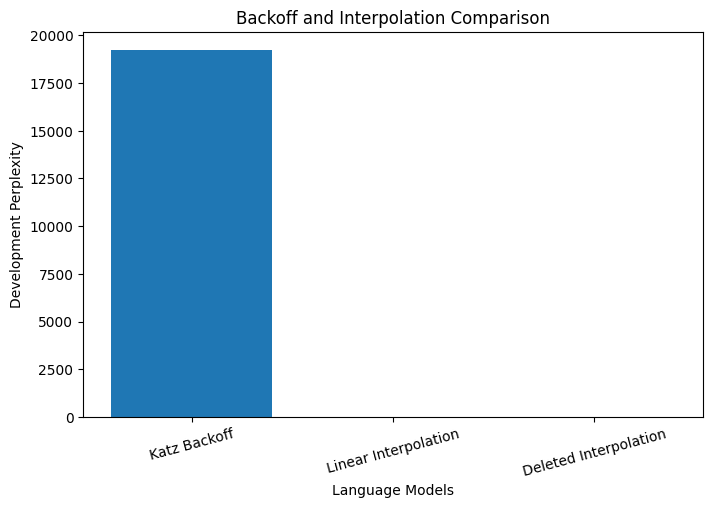


TASK 4 COMPLETED SUCCESSFULLY


In [ ]:

# TASK 4: BACKOFF AND DELETED INTERPOLATION

import re
import random
import math
from collections import Counter, defaultdict
from functools import lru_cache
import matplotlib.pyplot as plt

random.seed(42)

# ------------------------------------------------
# 1. TRANSPORT ENQUIRY CORPUS
# ------------------------------------------------

utterances = [
    "I want two tickets to Vellore",
    "What is the bus timing to Chennai",
    "Book a train ticket to Madurai",
    "When will the next bus arrive",
    "Tell me the ticket fare to Bangalore",
    "I want to cancel my bus ticket",
    "Is there a train from Chennai to Vellore",
    "What is the departure time of the bus",
    "I need a return ticket to Hyderabad",
    "Show me the available train timings",
    "How much is the fare to Madurai",
    "I want to book three bus tickets",
    "When does the first train leave",
    "Is the bus available today",
    "Tell me the arrival time of the train",
    "I need two tickets to Chennai",
    "What is the distance to Vellore",
    "Can I get a refund for my ticket",
    "Show the bus route to Bangalore",
    "When is the next train to Hyderabad",
    "Book a bus ticket from Chennai",
    "What time does the train arrive",
    "I need a ticket to Coimbatore",
    "Is there a bus to Tirupati",
    "Tell me the train fare to Vellore",
    "I want to book a return ticket",
    "When is the last bus to Madurai",
    "Can I change my train ticket",
    "Show available buses to Chennai",
    "How much does a train ticket cost"
]

# ------------------------------------------------
# 2. TOKENIZATION
# ------------------------------------------------

def tokenize(sentence):
    return re.findall(r"[a-z]+|\d+", sentence.lower())

sentences = [
    ["<s>"] + tokenize(s) + ["</s>"]
    for s in utterances
]

# ------------------------------------------------
# 3. SPLIT DATA
# 80% TRAIN, 10% DEVELOPMENT, 10% TEST
# ------------------------------------------------

indices = list(range(len(sentences)))
random.shuffle(indices)

n = len(indices)

train_end = int(0.80 * n)
dev_end = int(0.90 * n)

train = [sentences[i] for i in indices[:train_end]]
dev = [sentences[i] for i in indices[train_end:dev_end]]
test = [sentences[i] for i in indices[dev_end:]]

# Hold out 20% of training data for interpolation tuning
tune_end = int(0.80 * len(train))

fit_data = train[:tune_end]
tune_data = train[tune_end:]

print("Training sentences:", len(train))
print("Model-fitting sentences:", len(fit_data))
print("Interpolation tuning sentences:", len(tune_data))
print("Development sentences:", len(dev))
print("Test sentences:", len(test))

# ------------------------------------------------
# 4. BUILD N-GRAM COUNTS
# ------------------------------------------------

fit_vocabulary = set(
    word for sentence in fit_data for word in sentence
)

vocabulary = fit_vocabulary | {"<UNK>"}
V = len(vocabulary)

def replace_unknown(sentence):
    return [
        word if word in vocabulary else "<UNK>"
        for word in sentence
    ]

fit_data = [replace_unknown(s) for s in fit_data]
tune_data = [replace_unknown(s) for s in tune_data]
dev_data = [replace_unknown(s) for s in dev]
test_data = [replace_unknown(s) for s in test]

unigram_counts = Counter()
bigram_counts = Counter()
trigram_counts = Counter()

bigram_context = Counter()
trigram_context = Counter()

for sentence in fit_data:

    unigram_counts.update(sentence)

    for i in range(1, len(sentence)):
        w1 = sentence[i-1]
        w2 = sentence[i]

        bigram_counts[(w1, w2)] += 1
        bigram_context[w1] += 1

    for i in range(2, len(sentence)):
        w1, w2, w3 = sentence[i-2:i+1]

        trigram_counts[(w1, w2, w3)] += 1
        trigram_context[(w1, w2)] += 1

total_tokens = sum(unigram_counts.values())

print("\nVocabulary size:", V)
print("Unigram types:", len(unigram_counts))
print("Bigram types:", len(bigram_counts))
print("Trigram types:", len(trigram_counts))

# ------------------------------------------------
# 5. UNIGRAM, BIGRAM AND TRIGRAM MLE
# ------------------------------------------------

def unigram_prob(word):
    return (
        unigram_counts[word] + 1
    ) / (
        total_tokens + V
    )

def bigram_prob(w1, w2):
    if bigram_context[w1] == 0:
        return 0.0

    return (
        bigram_counts[(w1, w2)] /
        bigram_context[w1]
    )

def trigram_prob(w1, w2, w3):
    context = (w1, w2)

    if trigram_context[context] == 0:
        return 0.0

    return (
        trigram_counts[(w1, w2, w3)] /
        trigram_context[context]
    )

# ------------------------------------------------
# 6. GOOD-TURING DISCOUNT COUNTS
# ------------------------------------------------

bigram_Nr = Counter(bigram_counts.values())
trigram_Nr = Counter(trigram_counts.values())

def good_turing_discount(count, Nr):

    Nc = Nr.get(count, 0)
    Nc1 = Nr.get(count + 1, 0)

    if Nc > 0 and Nc1 > 0:
        revised = (count + 1) * Nc1 / Nc
    else:
        # Practical high-frequency fallback
        revised = count * 0.99

    # Prevent revised count from exceeding original count
    return max(0.0, min(count * 0.99, revised))

# ------------------------------------------------
# 7. KATZ BACKOFF WITH NORMALIZATION
# ------------------------------------------------

@lru_cache(maxsize=None)
def katz_bigram_alpha(context):

    seen = [
        word for word in vocabulary
        if bigram_counts[(context, word)] > 0
    ]

    remaining_mass = 1.0 - sum(
        good_turing_discount(
            bigram_counts[(context, word)], bigram_Nr
        ) / bigram_context[context]
        for word in seen
    )

    lower_seen_mass = sum(
        unigram_prob(word) for word in seen
    )

    lower_unseen_mass = max(
        0.0, 1.0 - lower_seen_mass
    )

    if lower_unseen_mass == 0:
        return 0.0

    return max(0.0, remaining_mass) / lower_unseen_mass


def katz_bigram(w1, w2):

    count = bigram_counts[(w1, w2)]

    if count > 0:
        return (
            good_turing_discount(count, bigram_Nr) /
            bigram_context[w1]
        )

    return katz_bigram_alpha(w1) * unigram_prob(w2)


@lru_cache(maxsize=None)
def katz_trigram_alpha(w1, w2):

    context = (w1, w2)

    seen = [
        word for word in vocabulary
        if trigram_counts[(w1, w2, word)] > 0
    ]

    if trigram_context[context] == 0:
        return 0.0

    remaining_mass = 1.0 - sum(
        good_turing_discount(
            trigram_counts[(w1, w2, word)], trigram_Nr
        ) / trigram_context[context]
        for word in seen
    )

    lower_seen_mass = sum(
        katz_bigram(w2, word) for word in seen
    )

    lower_unseen_mass = max(
        0.0, 1.0 - lower_seen_mass
    )

    if lower_unseen_mass <= 1e-12:
        return 0.0

    return max(0.0, remaining_mass) / lower_unseen_mass


def katz_trigram(w1, w2, w3):

    count = trigram_counts[(w1, w2, w3)]

    if count > 0:
        return (
            good_turing_discount(count, trigram_Nr) /
            trigram_context[(w1, w2)]
        )

    # Backoff to Katz bigram
    return (
        katz_trigram_alpha(w1, w2) *
        katz_bigram(w2, w3)
    )

# ------------------------------------------------
# 8. STUPID BACKOFF
# ------------------------------------------------

def stupid_backoff(w1, w2, w3, alpha=0.4):

    if trigram_counts[(w1, w2, w3)] > 0:
        return trigram_prob(w1, w2, w3)

    if bigram_counts[(w2, w3)] > 0:
        return alpha * bigram_prob(w2, w3)

    return alpha**2 * unigram_prob(w3)

# ------------------------------------------------
# 9. LINEAR INTERPOLATION
# ------------------------------------------------

def linear_interpolation(w1, w2, w3, lambdas):

    l1, l2, l3 = lambdas

    return (
        l1 * unigram_prob(w3) +
        l2 * bigram_prob(w2, w3) +
        l3 * trigram_prob(w1, w2, w3)
    )

# ------------------------------------------------
# 10. DELETED INTERPOLATION
# ESTIMATE LAMBDA WEIGHTS USING HELD-OUT DATA
# ------------------------------------------------

def context_band(count):

    if count <= 1:
        return "Low (1)"

    elif count <= 4:
        return "Medium (2-4)"

    return "High (5+)"

# Candidate lambda weights
candidates = []

for l1 in [i / 10 for i in range(11)]:
    for l2 in [i / 10 for i in range(11)]:
        l3 = round(1.0 - l1 - l2, 1)

        if l3 >= 0:
            candidates.append((l1, l2, l3))

# Prepare tuning events
tuning_events = []

for sentence in tune_data:
    for i in range(1, len(sentence)):

        w3 = sentence[i]
        w2 = sentence[i-1]
        w1 = sentence[i-2] if i >= 2 else "<s>"

        count = trigram_context[(w1, w2)]

        tuning_events.append(
            (w1, w2, w3, context_band(count))
        )

# Estimate weights separately for each context band
deleted_weights = {}

for band in ["Low (1)", "Medium (2-4)", "High (5+)"]:

    events = [
        event for event in tuning_events
        if event[3] == band
    ]

    best_weights = (0.2, 0.3, 0.5)
    best_score = float("-inf")

    if events:

        for weights in candidates:

            score = 0.0

            for w1, w2, w3, _ in events:

                p = linear_interpolation(
                    w1, w2, w3, weights
                )

                score += math.log(max(p, 1e-12))

            if score > best_score:
                best_score = score
                best_weights = weights

    deleted_weights[band] = best_weights

print("\nDELETED INTERPOLATION WEIGHTS")

for band, weights in deleted_weights.items():

    print(
        band,
        "Lambda 1:", weights[0],
        "Lambda 2:", weights[1],
        "Lambda 3:", weights[2]
    )

# ------------------------------------------------
# 11. PERPLEXITY EVALUATION
# ------------------------------------------------

def get_events(data):

    events = []

    for sentence in data:

        for i in range(1, len(sentence)):

            w3 = sentence[i]
            w2 = sentence[i-1]
            w1 = sentence[i-2] if i >= 2 else "<s>"

            events.append((w1, w2, w3))

    return events


def calculate_perplexity(data, model):

    events = get_events(data)

    if not events:
        return float("inf")

    log_sum = 0.0

    for w1, w2, w3 in events:

        if model == "katz":
            p = katz_trigram(w1, w2, w3)

        elif model == "linear":
            p = linear_interpolation(
                w1, w2, w3, (0.2, 0.3, 0.5)
            )

        elif model == "deleted":
            band = context_band(
                trigram_context[(w1, w2)]
            )

            weights = deleted_weights[band]

            p = linear_interpolation(
                w1, w2, w3, weights
            )

        else:
            raise ValueError("Unknown model")

        log_sum += math.log(max(p, 1e-12))

    cross_entropy = -log_sum / len(events)

    return math.exp(cross_entropy)


print("\nDEVELOPMENT SET PERPLEXITY")

katz_pp = calculate_perplexity(dev_data, "katz")
linear_pp = calculate_perplexity(dev_data, "linear")
deleted_pp = calculate_perplexity(dev_data, "deleted")

print("Katz Backoff Perplexity:", round(katz_pp, 4))
print("Linear Interpolation Perplexity:", round(linear_pp, 4))
print("Deleted Interpolation Perplexity:", round(deleted_pp, 4))

# ------------------------------------------------
# 12. HAND TRACE AN UNSEEN TRIGRAM
# ------------------------------------------------

print("\nHAND TRACE: UNSEEN TRIGRAM")

found = False

for sentence in dev_data:

    for i in range(1, len(sentence)):

        w3 = sentence[i]
        w2 = sentence[i-1]
        w1 = sentence[i-2] if i >= 2 else "<s>"

        if trigram_counts[(w1, w2, w3)] == 0:

            print("Trigram:", (w1, w2, w3))
            print("Trigram count:", 0)

            lower_bigram = katz_bigram(w2, w3)
            alpha = katz_trigram_alpha(w1, w2)

            katz_probability = katz_trigram(w1, w2, w3)

            band = context_band(
                trigram_context[(w1, w2)]
            )

            weights = deleted_weights[band]

            interpolation_probability = linear_interpolation(
                w1, w2, w3, weights
            )

            print("\nKATZ BACKOFF")
            print("Trigram unavailable: use lower-order model")
            print("Alpha:", alpha)
            print("Katz bigram probability:", lower_bigram)
            print("Katz trigram probability:", katz_probability)

            print("\nDELETED INTERPOLATION")
            print("Context band:", band)
            print("Lambda weights:", weights)
            print(
                "Unigram probability:", unigram_prob(w3)
            )
            print(
                "Bigram probability:", bigram_prob(w2, w3)
            )
            print("Trigram probability:", 0.0)
            print(
                "Interpolated probability:",
                interpolation_probability
            )

            found = True
            break

    if found:
        break

if not found:
    print("No unseen trigram found in the development set.")

# ------------------------------------------------
# 13. STUPID BACKOFF EXAMPLE
# ------------------------------------------------

print("\nSTUPID BACKOFF EXAMPLE")

if found:
    print(
        "Stupid Backoff score:",
        stupid_backoff(w1, w2, w3)
    )

# ------------------------------------------------
# 14. PERPLEXITY COMPARISON GRAPH
# ------------------------------------------------

models = [
    "Katz Backoff",
    "Linear Interpolation",
    "Deleted Interpolation"
]

perplexities = [
    katz_pp,
    linear_pp,
    deleted_pp
]

plt.figure(figsize=(8, 5))
plt.bar(models, perplexities)
plt.xlabel("Language Models")
plt.ylabel("Development Perplexity")
plt.title("Backoff and Interpolation Comparison")
plt.xticks(rotation=15)
plt.show()

print("\nTASK 4 COMPLETED SUCCESSFULLY")


Task 5

Training sentences: 24
Development sentences: 3
Test sentences: 3

DELETED INTERPOLATION WEIGHTS
Low : (0.0, 1.0, 0.0)
Medium : (1.0, 0.0, 0.0)
High : (0.2, 0.3, 0.5)

ENTROPY RESULTS
Uniform Entropy: 2.0 bits
Sharply Peaked Entropy: 0.8476 bits
Uneven Entropy: 1.6477 bits

Training unigram entropy: 4.9591 bits

DEVELOPMENT SET EVALUATION
     Model  Cross Entropy (bits/word)  Perplexity per Word  Average Utterance Perplexity
Unsmoothed                        inf                  inf                           inf
   Unigram                   5.320370            39.956821                     39.968156
    Bigram                   4.869309            29.228599                     30.208395
   Trigram                   5.342513            40.574813                     40.869207
     Add-k                   5.138097            35.214476                     35.624172
      Katz                   3.667415            12.705797                     14.153900
    Linear                   5.05783

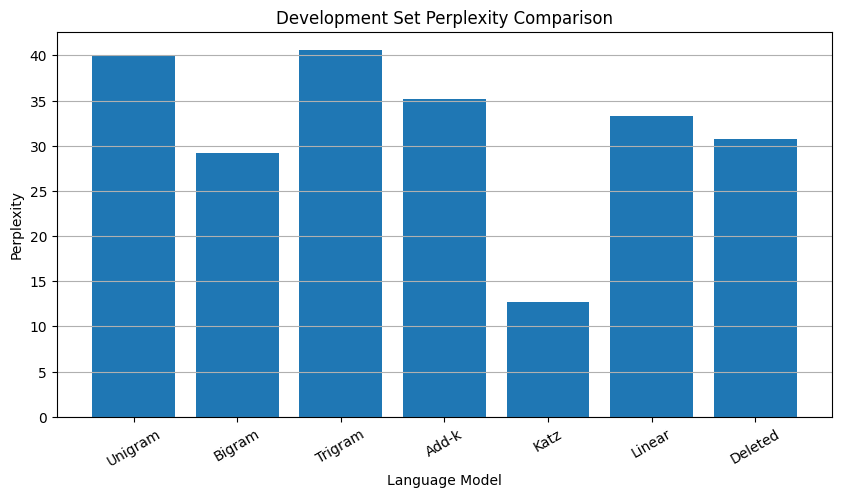


TASK 5 COMPLETED


In [ ]:

# TASK 5: ENTROPY, CROSS-ENTROPY AND PERPLEXITY

import re
import math
import random
import os
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter, defaultdict

random.seed(42)

# ------------------------------------------------
# 1. TRANSPORT ENQUIRY CORPUS
# ------------------------------------------------

utterances = [
    "I want two tickets to Vellore",
    "What is the bus timing to Chennai",
    "Book a train ticket to Madurai",
    "When will the next bus arrive",
    "Tell me the ticket fare to Bangalore",
    "I want to cancel my bus ticket",
    "Is there a train from Chennai to Vellore",
    "What is the departure time of the bus",
    "I need a return ticket to Hyderabad",
    "Show me the available train timings",
    "How much is the fare to Madurai",
    "I want to book three bus tickets",
    "When does the first train leave",
    "Is the bus available today",
    "Tell me the arrival time of the train",
    "I need two tickets to Chennai",
    "What is the distance to Vellore",
    "Can I get a refund for my ticket",
    "Show the bus route to Bangalore",
    "When is the next train to Hyderabad",
    "Book a bus ticket from Chennai",
    "What time does the train arrive",
    "I need a ticket to Coimbatore",
    "Is there a bus to Tirupati",
    "Tell me the train fare to Vellore",
    "I want to book a return ticket",
    "When is the last bus to Madurai",
    "Can I change my train ticket",
    "Show available buses to Chennai",
    "How much does a train ticket cost"
]

# ------------------------------------------------
# 2. TOKENIZATION
# ------------------------------------------------

def tokenize(text):
    return re.findall(r"[a-z]+|\d+", text.lower())

sentences = [
    ["<s>"] + tokenize(s) + ["</s>"]
    for s in utterances
]

# ------------------------------------------------
# 3. DATA SPLIT
# ------------------------------------------------

indices = list(range(len(sentences)))
random.shuffle(indices)

n = len(indices)

train_end = int(0.80 * n)
dev_end = int(0.90 * n)

train = [sentences[i] for i in indices[:train_end]]
dev = [sentences[i] for i in indices[train_end:dev_end]]
test = [sentences[i] for i in indices[dev_end:]]

# Hold out a portion of training data for deleted interpolation
fit_end = int(0.80 * len(train))

fit_data = train[:fit_end]
tune_data = train[fit_end:]

print("Training sentences:", len(train))
print("Development sentences:", len(dev))
print("Test sentences:", len(test))

# ------------------------------------------------
# 4. BUILD COMMON VOCABULARY
# ------------------------------------------------

word_counts = Counter(
    word for sentence in fit_data for word in sentence
)

# Use threshold 1 for this demonstration
vocabulary = set(word_counts)
vocabulary.add("<UNK>")

V = len(vocabulary)

def map_unk(sentence):
    return [
        word if word in vocabulary else "<UNK>"
        for word in sentence
    ]

fit_data = [map_unk(s) for s in fit_data]
tune_data = [map_unk(s) for s in tune_data]
dev_data = [map_unk(s) for s in dev]
test_data = [map_unk(s) for s in test]

# ------------------------------------------------
# 5. BUILD N-GRAM COUNTS
# ------------------------------------------------

unigram = Counter()
bigram = Counter()
trigram = Counter()

context1 = Counter()
context2 = Counter()

for sentence in fit_data:

    unigram.update(sentence)

    for i in range(1, len(sentence)):
        w1, w2 = sentence[i-1], sentence[i]
        bigram[(w1, w2)] += 1
        context1[w1] += 1

    for i in range(2, len(sentence)):
        w1, w2, w3 = sentence[i-2:i+1]
        trigram[(w1, w2, w3)] += 1
        context2[(w1, w2)] += 1

N = sum(unigram.values())

# ------------------------------------------------
# 6. UNIGRAM, BIGRAM AND TRIGRAM PROBABILITIES
# ------------------------------------------------

def p1(w):
    return (unigram[w] + 1) / (N + V)

def p2(w1, w2, k=1):
    return (
        bigram[(w1, w2)] + k
    ) / (
        context1[w1] + k * V
    )

def p3(w1, w2, w3, k=1):
    return (
        trigram[(w1, w2, w3)] + k
    ) / (
        context2[(w1, w2)] + k * V
    )

def unsmoothed_p1(w):
    return unigram[w] / N if N else 0

def unsmoothed_p2(w1, w2):
    if context1[w1] == 0:
        return 0
    return bigram[(w1, w2)] / context1[w1]

def unsmoothed_p3(w1, w2, w3):
    if context2[(w1, w2)] == 0:
        return 0
    return trigram[(w1, w2, w3)] / context2[(w1, w2)]

# ------------------------------------------------
# 7. KATZ-STYLE BACKOFF
# ------------------------------------------------

# Discount observed counts and normalize the leftover
# probability mass over unseen continuations.

def discounted_count(count, discount=0.75):
    if count == 0:
        return 0
    return max(0.0, count - discount)

def katz_bigram(w1, w2):

    seen = [
        word for word in vocabulary
        if bigram[(w1, word)] > 0
    ]

    if bigram[(w1, w2)] > 0:
        return (
            discounted_count(bigram[(w1, w2)]) /
            context1[w1]
        )

    discounted_seen_mass = sum(
        discounted_count(bigram[(w1, word)]) /
        context1[w1]
        for word in seen
    ) if context1[w1] else 0

    leftover = max(0.0, 1.0 - discounted_seen_mass)

    lower_unseen_mass = sum(
        p1(word) for word in vocabulary
        if word not in seen
    )

    alpha = (
        leftover / lower_unseen_mass
        if lower_unseen_mass > 0 else 0
    )

    return alpha * p1(w2)

def katz_trigram(w1, w2, w3):

    context = (w1, w2)

    seen = [
        word for word in vocabulary
        if trigram[(w1, w2, word)] > 0
    ]

    if trigram[(w1, w2, w3)] > 0:
        return (
            discounted_count(trigram[(w1, w2, w3)]) /
            context2[context]
        )

    discounted_seen_mass = sum(
        discounted_count(trigram[(w1, w2, word)]) /
        context2[context]
        for word in seen
    ) if context2[context] else 0

    leftover = max(0.0, 1.0 - discounted_seen_mass)

    lower_unseen_mass = sum(
        katz_bigram(w2, word)
        for word in vocabulary
        if word not in seen
    )

    alpha = (
        leftover / lower_unseen_mass
        if lower_unseen_mass > 0 else 0
    )

    return alpha * katz_bigram(w2, w3)

# ------------------------------------------------
# 8. LINEAR AND DELETED INTERPOLATION
# ------------------------------------------------

def interpolation(w1, w2, w3, weights):

    l1, l2, l3 = weights

    return (
        l1 * p1(w3) +
        l2 * p2(w2, w3) +
        l3 * p3(w1, w2, w3)
    )

# Estimate deleted interpolation weights
# on held-out training data using grid search.

candidates = []

for a in range(11):
    for b in range(11-a):
        c = 10-a-b
        candidates.append((a/10, b/10, c/10))

def context_band(count):
    if count <= 1:
        return "Low"
    elif count <= 4:
        return "Medium"
    return "High"

events = []

for sentence in tune_data:
    for i in range(1, len(sentence)):
        w3 = sentence[i]
        w2 = sentence[i-1]
        w1 = sentence[i-2] if i >= 2 else "<s>"

        band = context_band(context2[(w1, w2)])
        events.append((w1, w2, w3, band))

deleted_weights = {}

for band in ["Low", "Medium", "High"]:

    band_events = [
        e for e in events if e[3] == band
    ]

    best_weights = (0.2, 0.3, 0.5)
    best_score = float("-inf")

    if band_events:
        for weights in candidates:

            score = 0

            for w1, w2, w3, _ in band_events:
                prob = interpolation(w1, w2, w3, weights)
                score += math.log(max(prob, 1e-12))

            if score > best_score:
                best_score = score
                best_weights = weights

    deleted_weights[band] = best_weights

print("\nDELETED INTERPOLATION WEIGHTS")

for band, weights in deleted_weights.items():
    print(band, ":", weights)

# ------------------------------------------------
# 9. ENTROPY OF THREE DISTRIBUTIONS
# ------------------------------------------------

def entropy(probabilities):
    return -sum(
        p * math.log2(p)
        for p in probabilities if p > 0
    )

distributions = {
    "Uniform": [0.25, 0.25, 0.25, 0.25],
    "Sharply Peaked": [0.85, 0.05, 0.05, 0.05],
    "Uneven": [0.50, 0.30, 0.15, 0.05]
}

print("\nENTROPY RESULTS")

for name, distribution in distributions.items():
    print(name, "Entropy:", round(entropy(distribution), 4), "bits")

# ------------------------------------------------
# 10. ACTUAL CORPUS UNIGRAM ENTROPY
# ------------------------------------------------

actual_distribution = [
    count / N for count in unigram.values()
]

print(
    "\nTraining unigram entropy:",
    round(entropy(actual_distribution), 4),
    "bits"
)

# ------------------------------------------------
# 11. CROSS-ENTROPY AND PERPLEXITY
# ------------------------------------------------

def model_probability(model, w1, w2, w3):

    if model == "Unigram":
        return p1(w3)

    if model == "Bigram":
        return p2(w2, w3)

    if model == "Trigram":
        return p3(w1, w2, w3)

    if model == "Add-k":
        return p3(w1, w2, w3, k=0.5)

    if model == "Katz":
        return katz_trigram(w1, w2, w3)

    if model == "Linear":
        return interpolation(w1, w2, w3, (0.2, 0.3, 0.5))

    if model == "Deleted":
        band = context_band(context2[(w1, w2)])
        return interpolation(
            w1, w2, w3, deleted_weights[band]
        )

    if model == "Unsmoothed":
        return unsmoothed_p3(w1, w2, w3)

    raise ValueError("Unknown model")

def evaluate_model(data, model):

    all_log = 0.0
    total_words = 0
    sentence_perplexities = []

    for sentence in data:

        sentence_log = 0.0
        sentence_words = 0

        for i in range(1, len(sentence)):

            w3 = sentence[i]
            w2 = sentence[i-1]
            w1 = sentence[i-2] if i >= 2 else "<s>"

            prob = model_probability(model, w1, w2, w3)

            if prob <= 0:
                sentence_log = float("-inf")
                all_log = float("-inf")
                sentence_words += 1
                total_words += 1
                break

            sentence_log += math.log2(prob)
            all_log += math.log2(prob)

            sentence_words += 1
            total_words += 1

        if sentence_words and math.isfinite(sentence_log):
            sentence_perplexities.append(
                2 ** (-sentence_log / sentence_words)
            )
        else:
            sentence_perplexities.append(float("inf"))

    if total_words == 0 or not math.isfinite(all_log):
        return float("inf"), float("inf"), float("inf")

    cross_entropy = -all_log / total_words
    word_perplexity = 2 ** cross_entropy

    average_utterance_perplexity = (
        sum(sentence_perplexities) /
        len(sentence_perplexities)
        if sentence_perplexities else float("inf")
    )

    return (
        cross_entropy,
        word_perplexity,
        average_utterance_perplexity
    )

models = [
    "Unsmoothed",
    "Unigram",
    "Bigram",
    "Trigram",
    "Add-k",
    "Katz",
    "Linear",
    "Deleted"
]

results = []

print("\nDEVELOPMENT SET EVALUATION")

for model in models:

    ce, pp, utt_pp = evaluate_model(dev_data, model)

    results.append({
        "Model": model,
        "Cross Entropy (bits/word)": ce,
        "Perplexity per Word": pp,
        "Average Utterance Perplexity": utt_pp
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# ------------------------------------------------
# 12. UNFAIR PERPLEXITY COMPARISON
# ------------------------------------------------

print("\nUNFAIR COMPARISON DEMONSTRATION")

# Model A maps unseen words to UNK.
# Model B retains a different vocabulary.
# Their perplexities are not directly comparable.

print(
    "Model A and Model B must use the same vocabulary "
    "and the same UNK treatment."
)

print(
    "Using different vocabularies can distort the "
    "perplexity comparison."
)

# ------------------------------------------------
# 13. WORD ERROR RATE
# ------------------------------------------------

def edit_distance(reference, hypothesis):

    r = tokenize(reference)
    h = tokenize(hypothesis)

    dp = [[0] * (len(h)+1) for _ in range(len(r)+1)]

    for i in range(len(r)+1):
        dp[i][0] = i

    for j in range(len(h)+1):
        dp[0][j] = j

    for i in range(1, len(r)+1):
        for j in range(1, len(h)+1):

            cost = 0 if r[i-1] == h[j-1] else 1

            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )

    return dp[-1][-1]

def wer(references, hypotheses):

    total_errors = 0
    total_reference_words = 0

    for ref, hyp in zip(references, hypotheses):
        total_errors += edit_distance(ref, hyp)
        total_reference_words += len(tokenize(ref))

    return (
        total_errors / total_reference_words * 100
        if total_reference_words else 0
    )

# ------------------------------------------------
# 14. OPTIONAL ASR RESCORING WITH 200 HYPOTHESIS SETS
# ------------------------------------------------

# Prepare a CSV file named asr_hypotheses.csv
# Required columns:
# reference, hyp1, hyp2, hyp3, hyp4, hyp5

asr_file = "/content/asr_hypotheses.csv"

if os.path.exists(asr_file):

    asr_df = pd.read_csv(asr_file)

    required = [
        "reference", "hyp1", "hyp2", "hyp3", "hyp4", "hyp5"
    ]

    if not all(col in asr_df.columns for col in required):
        print("ASR CSV is missing required columns.")

    elif len(asr_df) < 200:
        print("Warning: Assignment requires at least 200 ASR sets.")

    else:

        asr_df = asr_df.head(200)

        references = asr_df["reference"].astype(str).tolist()

        # Baseline: choose first ASR hypothesis
        baseline = asr_df["hyp1"].astype(str).tolist()

        # Rescore using the deleted interpolation model
        rescored = []

        for _, row in asr_df.iterrows():

            hypotheses = [
                str(row[f"hyp{i}"]) for i in range(1, 6)
            ]

            best_hypothesis = None
            best_score = float("-inf")

            for hypothesis in hypotheses:

                words = map_unk(
                    ["<s>"] + tokenize(hypothesis) + ["</s>"]
                )

                score = 0.0

                for i in range(1, len(words)):

                    w3 = words[i]
                    w2 = words[i-1]
                    w1 = words[i-2] if i >= 2 else "<s>"

                    band = context_band(context2[(w1, w2)])
                    weights = deleted_weights[band]

                    prob = interpolation(w1, w2, w3, weights)

                    score += math.log(max(prob, 1e-12))

                if score > best_score:
                    best_score = score
                    best_hypothesis = hypothesis

            rescored.append(best_hypothesis)

        before_wer = wer(references, baseline)
        after_wer = wer(references, rescored)

        print("\nASR RESCORING RESULTS")
        print("Number of hypothesis sets:", len(asr_df))
        print("WER before rescoring:", round(before_wer, 2), "%")
        print("WER after rescoring:", round(after_wer, 2), "%")

else:
    print("\nASR RESCORING NOT RUN")
    print("Upload asr_hypotheses.csv with 200 hypothesis sets.")
    print("Required columns: reference, hyp1, hyp2, hyp3, hyp4, hyp5")

# ------------------------------------------------
# 15. PERPLEXITY GRAPH
# ------------------------------------------------

plot_df = results_df[
    results_df["Perplexity per Word"] != float("inf")
]

plt.figure(figsize=(10, 5))
plt.bar(
    plot_df["Model"],
    plot_df["Perplexity per Word"]
)

plt.xlabel("Language Model")
plt.ylabel("Perplexity")
plt.title("Development Set Perplexity Comparison")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.show()

print("\nTASK 5 COMPLETED")


Task 6

Dataset loaded successfully!
First 5 rows:
   sentence_id                 sentence token  tag annotator1 annotator2
0            1  I want to book a ticket     I  PRP        PRP        PRP
1            1  I want to book a ticket  want  VBP        VBP        VBP
2            1  I want to book a ticket    to   TO         TO         TO
3            1  I want to book a ticket  book   VB         VB         VB
4            1  I want to book a ticket     a   DT         DT         DT

DATASET INFORMATION
-------------------
Total tokens: 3000
Unique words: 68
Number of sentences: 625

OPEN-CLASS WORDS
Nouns : ['bus', 'train', 'ticket', 'station']
Verbs : ['book', 'travel', 'arrive', 'cancel']
Adjectives : ['fast', 'late', 'cheap', 'fresh']
Adverbs : ['quickly', 'today', 'tomorrow', 'soon']

CLOSED-CLASS WORDS
Pronouns : ['I', 'you', 'we', 'they']
Prepositions : ['to', 'from', 'at', 'in']
Determiners : ['a', 'an', 'the', 'this']
Conjunctions : ['and', 'but', 'or', 'because']
Auxiliaries : ['is'

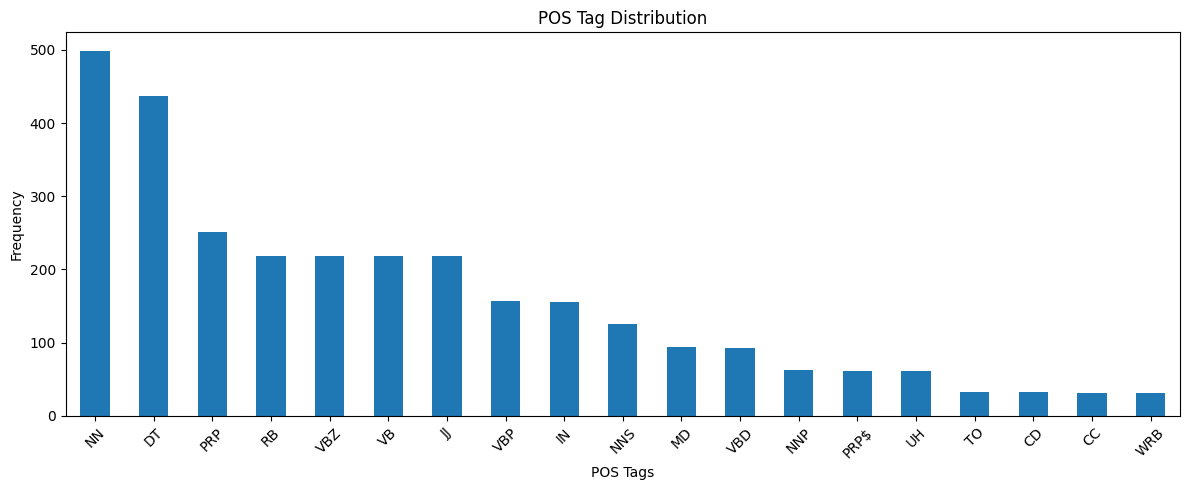


AMBIGUOUS WORD ANALYSIS

Word: book
               sentence token tag
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can book online  book  VB
I want to book a ticket  book  VB
    She can

In [2]:

# TASK 6: ENGLISH WORD CLASSES AND TAGSET DESIGN

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score

# STEP 1: Load dataset
file_path = "/content/task6_pos_data_practice.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("First 5 rows:")
print(df.head())

# STEP 2: Dataset information
print("\nDATASET INFORMATION")
print("-------------------")
print("Total tokens:", len(df))
print("Unique words:", df["token"].str.lower().nunique())
print("Number of sentences:", df["sentence_id"].nunique())

# STEP 3: Open-class and closed-class words

open_class = {
    "Nouns": ["bus", "train", "ticket", "station"],
    "Verbs": ["book", "travel", "arrive", "cancel"],
    "Adjectives": ["fast", "late", "cheap", "fresh"],
    "Adverbs": ["quickly", "today", "tomorrow", "soon"]
}

closed_class = {
    "Pronouns": ["I", "you", "we", "they"],
    "Prepositions": ["to", "from", "at", "in"],
    "Determiners": ["a", "an", "the", "this"],
    "Conjunctions": ["and", "but", "or", "because"],
    "Auxiliaries": ["is", "are", "was", "can"]
}

print("\nOPEN-CLASS WORDS")
for category, words in open_class.items():
    print(category, ":", words)

print("\nCLOSED-CLASS WORDS")
for category, words in closed_class.items():
    print(category, ":", words)

# STEP 4: POS tagset with Penn Treebank mapping

tagset = [
    "CC", "CD", "DT", "EX", "FW",
    "IN", "JJ", "JJR", "JJS", "MD",
    "NN", "NNS", "NNP", "NNPS",
    "PDT", "POS", "PRP", "PRP$",
    "RB", "RBR", "RBS", "RP",
    "TO", "UH", "VB"
]

print("\nPOS TAGSET MAPPING")
for tag in tagset:
    print(tag, "->", tag)

used_tags = set(df["tag"].dropna().str.upper())
print("\nTags used in dataset:", sorted(used_tags))
print("Number of unique tags:", len(used_tags))

# STEP 5: POS tag distribution

tag_distribution = df["tag"].value_counts()

print("\nPOS TAG DISTRIBUTION")
print(tag_distribution)

plt.figure(figsize=(12, 5))
tag_distribution.plot(kind="bar")
plt.title("POS Tag Distribution")
plt.xlabel("POS Tags")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# STEP 6: Ambiguous word analysis

ambiguous_words = ["book", "return", "train", "can", "light"]

print("\nAMBIGUOUS WORD ANALYSIS")

for word in ambiguous_words:
    result = df[df["token"].str.lower() == word]

    print("\nWord:", word)

    if len(result) > 0:
        print(result[["sentence", "token", "tag"]].to_string(index=False))
    else:
        print("Word not found in dataset.")

# STEP 7: Inter-annotator agreement

double_data = df.dropna(
    subset=["annotator1", "annotator2"]
).copy()

print("\nINTER-ANNOTATOR AGREEMENT")
print("-------------------------")
print("Double annotated tokens:", len(double_data))

if len(double_data) > 0:

    annotator1 = double_data["annotator1"].str.upper()
    annotator2 = double_data["annotator2"].str.upper()

    agreement = (annotator1 == annotator2).mean() * 100

    kappa = cohen_kappa_score(
        annotator1,
        annotator2
    )

    print("Percentage Agreement:", round(agreement, 2), "%")
    print("Cohen's Kappa:", round(kappa, 4))

else:
    print("No double-annotated data found.")

# STEP 8: Assignment requirement check

print("\nASSIGNMENT REQUIREMENT CHECK")
print("-----------------------------")

if len(df) >= 3000:
    print("3000 tokens requirement: SATISFIED")
else:
    print("3000 tokens requirement: NOT SATISFIED")

if len(double_data) >= 500:
    print("500 double-annotated tokens: SATISFIED")
else:
    print("500 double-annotated tokens: NOT SATISFIED")

if 20 <= len(used_tags) <= 30:
    print("20-30 POS tags requirement: SATISFIED")
else:
    print("20-30 POS tags requirement: NOT SATISFIED")

# STEP 9: Save results

tag_distribution.to_csv(
    "/content/Task6_Tag_Distribution.csv"
)

double_data.to_csv(
    "/content/Task6_Double_Annotated_Data.csv",
    index=False
)

print("\nTask 6 analysis completed successfully!")
print("Output files saved successfully.")


Task 7

Dataset loaded successfully!
   sentence_id                 sentence token  tag annotator1 annotator2
0            1  I want to book a ticket     I  PRP        PRP        PRP
1            1  I want to book a ticket  want  VBP        VBP        VBP
2            1  I want to book a ticket    to   TO         TO         TO
3            1  I want to book a ticket  book   VB         VB         VB
4            1  I want to book a ticket     a   DT         DT         DT

PREDICTED POS TAGS
 sentence_id      token tag predicted_tag
           3         We PRP           PRP
           3       need VBP           VBD
           3        two  CD            JJ
           3    tickets NNS           NNS
           3      today  RB            RB
          11        She PRP           PRP
          11        can  MD            MD
          11       book  VB            VB
          11     online  RB            RB
          25        Can  MD            MD
          25        you PRP           PRP
         

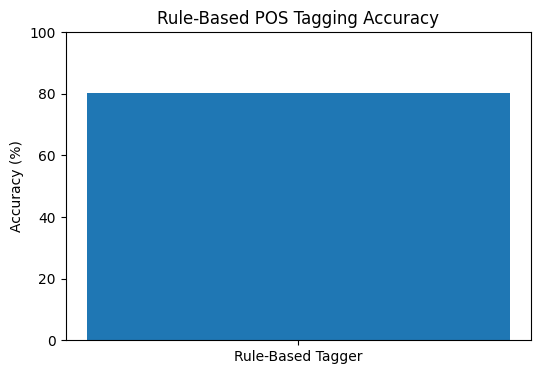


Task 7 completed successfully!
Results saved successfully.


In [3]:

# TASK 7: RULE-BASED POS TAGGING

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, classification_report

# STEP 1: Load dataset

file_path = "/content/task6_pos_data_practice.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(df.head())

# STEP 2: Data preprocessing

df = df.dropna(subset=["sentence_id", "token", "tag"])
df["token"] = df["token"].astype(str)
df["tag"] = df["tag"].astype(str).str.upper()

# Split by sentence to prevent sentence leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(df, groups=df["sentence_id"])
)

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

# STEP 3: Build word dictionary

word_dictionary = {}

for _, row in train.iterrows():
    word = row["token"].lower()
    tag = row["tag"]

    if word not in word_dictionary:
        word_dictionary[word] = {}

    word_dictionary[word][tag] = (
        word_dictionary[word].get(tag, 0) + 1
    )

# Most frequent tag for each word
most_frequent_tag = {
    word: max(tags, key=tags.get)
    for word, tags in word_dictionary.items()
}

# STEP 4: Define 15 rule-based conditions

def rule_based_tagger(tokens):

    predicted_tags = []

    for i, token in enumerate(tokens):

        word = token.lower()
        prev_word = tokens[i-1].lower() if i > 0 else ""
        next_word = tokens[i+1].lower() if i < len(tokens)-1 else ""

        # Initial dictionary tag
        tag = most_frequent_tag.get(word, "NN")

        # Rule 1: Pronouns
        if word in ["i", "you", "he", "she", "we", "they", "it"]:
            tag = "PRP"

        # Rule 2: Determiners
        elif word in ["a", "an", "the", "this", "that", "these"]:
            tag = "DT"

        # Rule 3: Prepositions
        elif word in ["to", "from", "at", "in", "on", "by", "near"]:
            tag = "IN"

        # Rule 4: Modal verbs
        elif word in ["can", "will", "could", "should", "would", "may"]:
            tag = "MD"

        # Rule 5: Conjunctions
        elif word in ["and", "but", "or", "because"]:
            tag = "CC"

        # Rule 6: Numbers
        elif word.isdigit():
            tag = "CD"

        # Rule 7: Words ending in ing
        elif word.endswith("ing"):
            tag = "VBG"

        # Rule 8: Words ending in ed
        elif word.endswith("ed"):
            tag = "VBD"

        # Rule 9: Words ending in ly
        elif word.endswith("ly"):
            tag = "RB"

        # Rule 10: Comparative adjectives
        elif word.endswith("er") and len(word) > 3:
            tag = "JJR"

        # Rule 11: Superlative adjectives
        elif word.endswith("est") and len(word) > 4:
            tag = "JJS"

        # Rule 12: Adjective before a noun
        elif next_word in most_frequent_tag and \
             most_frequent_tag[next_word] in ["NN", "NNS"]:
            if tag not in ["NN", "NNS", "NNP"]:
                tag = "JJ"

        # Rule 13: Proper nouns beginning with capital
        elif token[0].isupper():
            tag = "NNP"

        # Rule 14: Base verb after 'to'
        elif prev_word == "to":
            tag = "VB"

        # Rule 15: Plural words
        elif word.endswith("s") and len(word) > 2:
            tag = "NNS"

        predicted_tags.append(tag)

    return predicted_tags

# STEP 5: Predict POS tags

test["predicted_tag"] = ""

for sentence_id, group in test.groupby("sentence_id", sort=False):

    tokens = group["token"].tolist()
    predictions = rule_based_tagger(tokens)

    test.loc[group.index, "predicted_tag"] = predictions

print("\nPREDICTED POS TAGS")
print(test[[
    "sentence_id", "token", "tag", "predicted_tag"
]].head(30).to_string(index=False))

# STEP 6: Calculate accuracy

accuracy = accuracy_score(
    test["tag"],
    test["predicted_tag"]
)

print("\nRULE-BASED TAGGER ACCURACY")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    test["tag"],
    test["predicted_tag"],
    zero_division=0
))

# STEP 7: Ambiguous word analysis

ambiguous_words = ["book", "return", "train", "can", "light"]

print("\nAMBIGUOUS WORD ANALYSIS")

for word in ambiguous_words:

    subset = test[
        test["token"].str.lower() == word
    ]

    if len(subset) > 0:
        correct = (subset["tag"] == subset["predicted_tag"]).mean()

        print("\nWord:", word)
        print(subset[[
            "token", "tag", "predicted_tag"
        ]].to_string(index=False))

        print("Accuracy:", round(correct * 100, 2), "%")

# STEP 8: Common error analysis

errors = test[
    test["tag"] != test["predicted_tag"]
].copy()

print("\nCOMMON TAGGING ERRORS")

if len(errors) > 0:

    errors["Error_Type"] = (
        errors["tag"] + " predicted as " +
        errors["predicted_tag"]
    )

    print(errors["Error_Type"].value_counts().head(5))

else:
    print("No tagging errors found.")

# STEP 9: Rule conflict examples

print("\nRULE-BASED TAGGING EXAMPLES")

example_sentences = [
    ["I", "want", "to", "book", "tickets"],
    ["The", "train", "arrives", "today"],
    ["We", "need", "a", "return", "ticket"]
]

for sentence in example_sentences:
    result = rule_based_tagger(sentence)

    print("\nSentence:", " ".join(sentence))
    print("Tokens:", sentence)
    print("Predicted Tags:", result)

# STEP 10: Plot accuracy

plt.figure(figsize=(6, 4))

plt.bar(
    ["Rule-Based Tagger"],
    [accuracy * 100]
)

plt.title("Rule-Based POS Tagging Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

# STEP 11: Save results

test.to_csv(
    "/content/Task7_RuleBased_Results.csv",
    index=False
)

errors.to_csv(
    "/content/Task7_Tagging_Errors.csv",
    index=False
)

print("\nTask 7 completed successfully!")
print("Results saved successfully.")


Task 8

Dataset loaded successfully!
   sentence_id                 sentence token  tag annotator1 annotator2
0            1  I want to book a ticket     I  PRP        PRP        PRP
1            1  I want to book a ticket  want  VBP        VBP        VBP
2            1  I want to book a ticket    to   TO         TO         TO
3            1  I want to book a ticket  book   VB         VB         VB
4            1  I want to book a ticket     a   DT         DT         DT

TRAINING SENTENCES: 500
TESTING SENTENCES: 125

HMM TAGS:
['CC', 'CD', 'DT', 'IN', 'JJ', 'MD', 'NN', 'NNP', 'NNS', 'PRP', 'PRP$', 'RB', 'TO', 'UH', 'VB', 'VBD', 'VBP', 'VBZ', 'WRB']

TAGGING ACCURACY
----------------
HMM Accuracy: 100.0 %
MFT Baseline Accuracy: 99.34 %

HMM CLASSIFICATION REPORT
              precision    recall  f1-score   support

          CC       1.00      1.00      1.00        10
          CD       1.00      1.00      1.00         4
          DT       1.00      1.00      1.00        79
          IN      

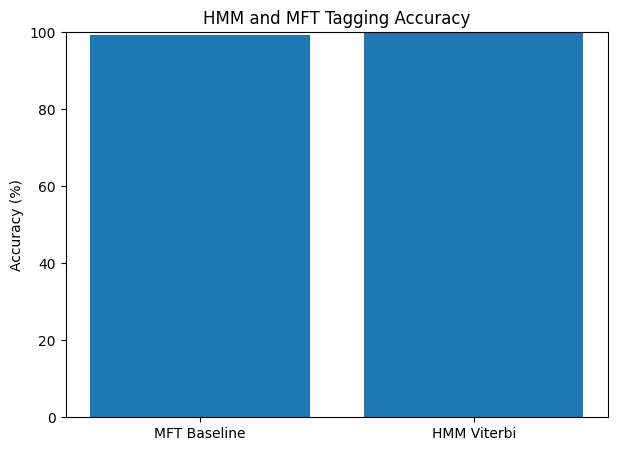


TASK 8 COMPLETED SUCCESSFULLY!
Results saved successfully.


In [4]:

# TASK 8: STOCHASTIC HMM TAGGING AND VITERBI ALGORITHM

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import itertools
from collections import Counter, defaultdict
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, classification_report

# ------------------------------------------------
# STEP 1: LOAD DATASET
# ------------------------------------------------

file_path = "/content/task6_pos_data_practice.csv"
df = pd.read_csv(file_path)

df = df.dropna(subset=["sentence_id", "token", "tag"]).copy()
df["token"] = df["token"].astype(str)
df["tag"] = df["tag"].astype(str).str.upper()

print("Dataset loaded successfully!")
print(df.head())

# ------------------------------------------------
# STEP 2: TRAIN-TEST SPLIT BY SENTENCE
# ------------------------------------------------

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(df, groups=df["sentence_id"])
)

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

# Create sentence sequences
def make_sentences(data):
    sentences = []

    for sid, group in data.groupby("sentence_id", sort=False):
        words = group["token"].tolist()
        tags = group["tag"].tolist()
        sentences.append((words, tags))

    return sentences

train_sentences = make_sentences(train)
test_sentences = make_sentences(test)

print("\nTRAINING SENTENCES:", len(train_sentences))
print("TESTING SENTENCES:", len(test_sentences))

# ------------------------------------------------
# STEP 3: HMM MODEL COUNTS
# ------------------------------------------------

transition_counts = defaultdict(Counter)
emission_counts = defaultdict(Counter)
tag_counts = Counter()
vocabulary_counts = Counter()
all_tags = set()

for words, tags in train_sentences:

    previous_tag = "<START>"

    for word, tag in zip(words, tags):

        word = word.lower()

        transition_counts[previous_tag][tag] += 1
        emission_counts[tag][word] += 1
        tag_counts[tag] += 1
        vocabulary_counts[word] += 1
        all_tags.add(tag)

        previous_tag = tag

    transition_counts[previous_tag]["<END>"] += 1

all_tags = sorted(all_tags)
V = len(vocabulary_counts) + 1

print("\nHMM TAGS:")
print(all_tags)

# ------------------------------------------------
# STEP 4: UNKNOWN WORD HANDLING
# ------------------------------------------------

def word_signature(word):
    if word and word[0].isupper():
        return "<CAP>"

    if word.isdigit():
        return "<NUM>"

    word = word.lower()

    if word.endswith("ing"):
        return "<ING>"

    if word.endswith("ed"):
        return "<ED>"

    if word.endswith("ly"):
        return "<LY>"

    if word.endswith("s"):
        return "<PLURAL>"

    return "<UNK>"

def emission_symbol(word):
    word = word.lower()

    if vocabulary_counts[word] <= 1:
        return word_signature(word)

    return word

# ------------------------------------------------
# STEP 5: ADD-ONE SMOOTHING
# ------------------------------------------------

alpha = 1.0

def transition_probability(previous_tag, current_tag):

    count = transition_counts[previous_tag][current_tag]
    total = sum(transition_counts[previous_tag].values())

    number_of_options = len(all_tags) + 1

    return (
        (count + alpha) /
        (total + alpha * number_of_options)
    )

def emission_probability(tag, word):

    symbol = emission_symbol(word)

    count = emission_counts[tag][symbol]
    total = sum(emission_counts[tag].values())

    emission_vocabulary_size = (
        len(vocabulary_counts) + 6
    )

    return (
        (count + alpha) /
        (total + alpha * emission_vocabulary_size)
    )

# ------------------------------------------------
# STEP 6: VITERBI ALGORITHM
# ------------------------------------------------

def viterbi(words, return_trellis=False):

    n = len(words)
    m = len(all_tags)

    trellis = np.full((n, m), -np.inf)
    backpointer = np.zeros((n, m), dtype=int)

    # Initialization
    for j, tag in enumerate(all_tags):

        trellis[0, j] = (
            np.log(transition_probability("<START>", tag)) +
            np.log(emission_probability(tag, words[0]))
        )

    # Recursion
    for t in range(1, n):

        for j, current_tag in enumerate(all_tags):

            scores = []

            for i, previous_tag in enumerate(all_tags):

                score = (
                    trellis[t-1, i] +
                    np.log(transition_probability(
                        previous_tag, current_tag
                    )) +
                    np.log(emission_probability(
                        current_tag, words[t]
                    ))
                )

                scores.append(score)

            best_previous = np.argmax(scores)

            trellis[t, j] = scores[best_previous]
            backpointer[t, j] = best_previous

    # Termination
    final_scores = []

    for j, tag in enumerate(all_tags):

        final_scores.append(
            trellis[n-1, j] +
            np.log(transition_probability(tag, "<END>"))
        )

    best_last = np.argmax(final_scores)

    # Backtracking
    best_path = [best_last]

    for t in range(n-1, 0, -1):

        best_path.append(
            backpointer[t, best_path[-1]]
        )

    best_path.reverse()

    predicted_tags = [
        all_tags[index] for index in best_path
    ]

    if return_trellis:
        return predicted_tags, trellis, backpointer

    return predicted_tags

# ------------------------------------------------
# STEP 7: PREDICT TEST DATA
# ------------------------------------------------

true_tags = []
hmm_predictions = []
mft_predictions = []
test_words = []

mft_tag = {}

for word, tag_counter in emission_counts.items():
    pass

# Most frequent tag for each training word
word_tag_counts = defaultdict(Counter)

for words, tags in train_sentences:
    for word, tag in zip(words, tags):
        word_tag_counts[word.lower()][tag] += 1

for words, tags in test_sentences:

    predictions = viterbi(words)

    for word, true_tag, predicted_tag in zip(
        words, tags, predictions
    ):

        test_words.append(word)
        true_tags.append(true_tag)
        hmm_predictions.append(predicted_tag)

        if word.lower() in word_tag_counts:
            baseline_tag = word_tag_counts[
                word.lower()
            ].most_common(1)[0][0]
        else:
            baseline_tag = tag_counts.most_common(1)[0][0]

        mft_predictions.append(baseline_tag)

# ------------------------------------------------
# STEP 8: ACCURACY COMPARISON
# ------------------------------------------------

hmm_accuracy = accuracy_score(
    true_tags, hmm_predictions
)

mft_accuracy = accuracy_score(
    true_tags, mft_predictions
)

print("\nTAGGING ACCURACY")
print("----------------")
print("HMM Accuracy:", round(hmm_accuracy * 100, 2), "%")
print("MFT Baseline Accuracy:", round(mft_accuracy * 100, 2), "%")

print("\nHMM CLASSIFICATION REPORT")

print(classification_report(
    true_tags,
    hmm_predictions,
    zero_division=0
))

# ------------------------------------------------
# STEP 9: UNKNOWN WORD ACCURACY
# ------------------------------------------------

oov_indices = [
    i for i, word in enumerate(test_words)
    if word.lower() not in vocabulary_counts
]

if oov_indices:

    oov_true = [true_tags[i] for i in oov_indices]
    oov_pred = [hmm_predictions[i] for i in oov_indices]

    oov_accuracy = accuracy_score(oov_true, oov_pred)

else:
    oov_accuracy = None

print("\nUNKNOWN WORD ANALYSIS")
print("---------------------")
print("Unknown word count:", len(oov_indices))

if oov_accuracy is not None:
    print("OOV Tagging Accuracy:",
          round(oov_accuracy * 100, 2), "%")
else:
    print("No unknown words found in test data.")

# ------------------------------------------------
# STEP 10: VITERBI TRELLIS AND BACKPOINTER
# ------------------------------------------------

sample_words = test_sentences[0][0][:5]

sample_prediction, trellis, backpointer = viterbi(
    sample_words,
    return_trellis=True
)

print("\nVITERBI SAMPLE TRACE")
print("--------------------")
print("Input words:", sample_words)
print("Predicted tags:", sample_prediction)

print("\nTRELLIS PROBABILITIES (LOG VALUES)")

trellis_df = pd.DataFrame(
    trellis,
    index=sample_words,
    columns=all_tags
)

print(trellis_df.round(3))

print("\nBACKPOINTER TABLE")

backpointer_tags = pd.DataFrame(
    [
        ["-" if t == 0 else all_tags[x]
         for x in row]
        for t, row in enumerate(backpointer)
    ],
    index=sample_words,
    columns=all_tags
)

print(backpointer_tags)

# ------------------------------------------------
# STEP 11: EXHAUSTIVE SEARCH COMPARISON
# ------------------------------------------------

short_words = sample_words[:5]

# Use the three most frequent tags as candidates
candidate_tags = [
    tag for tag, count in tag_counts.most_common(3)
]

best_sequence = None
best_score = -np.inf
combinations_checked = 0

for sequence in itertools.product(
    candidate_tags, repeat=len(short_words)
):

    score = (
        np.log(transition_probability("<START>", sequence[0])) +
        np.log(emission_probability(sequence[0], short_words[0]))
    )

    for i in range(1, len(short_words)):

        score += np.log(
            transition_probability(sequence[i-1], sequence[i])
        )

        score += np.log(
            emission_probability(sequence[i], short_words[i])
        )

    score += np.log(
        transition_probability(sequence[-1], "<END>")
    )

    combinations_checked += 1

    if score > best_score:
        best_score = score
        best_sequence = sequence

print("\nEXHAUSTIVE SEARCH")
print("-----------------")
print("Input words:", short_words)
print("Candidate tags:", candidate_tags)
print("Combinations checked:", combinations_checked)
print("Best exhaustive sequence:", list(best_sequence))
print("Viterbi sequence:", viterbi(short_words))

# ------------------------------------------------
# STEP 12: PLOT ACCURACY COMPARISON
# ------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    ["MFT Baseline", "HMM Viterbi"],
    [mft_accuracy * 100, hmm_accuracy * 100]
)

plt.title("HMM and MFT Tagging Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

# ------------------------------------------------
# STEP 13: SAVE RESULTS
# ------------------------------------------------

results = pd.DataFrame({
    "token": test_words,
    "actual_tag": true_tags,
    "HMM_predicted_tag": hmm_predictions,
    "MFT_predicted_tag": mft_predictions
})

results.to_csv(
    "/content/Task8_HMM_Results.csv",
    index=False
)

trellis_df.to_csv(
    "/content/Task8_Viterbi_Trellis.csv"
)

print("\nTASK 8 COMPLETED SUCCESSFULLY!")
print("Results saved successfully.")


Task 9

Dataset loaded successfully!
   sentence_id                 sentence token  tag annotator1 annotator2
0            1  I want to book a ticket     I  PRP        PRP        PRP
1            1  I want to book a ticket  want  VBP        VBP        VBP
2            1  I want to book a ticket    to   TO         TO         TO
3            1  I want to book a ticket  book   VB         VB         VB
4            1  I want to book a ticket     a   DT         DT         DT

TRAINING SENTENCES: 437
VALIDATION SENTENCES: 94
TEST SENTENCES: 94

TAGGING ACCURACY
----------------
Initial MFT Accuracy: 100.0 %
Brill Tagger Accuracy: 100.0 %
Learned Rules: 1

FIRST 10 TRANSFORMATION RULES
 Rule_Number Template Condition Old_Tag New_Tag  Corrected_Errors  Introduced_Errors  Net_Gain
           1 PREV_TAG        MD      NN      VB                24                  0        24

BEST RULE COUNT: 1
BEST VALIDATION ACCURACY: 100.0 %
Selected-rule TEST Accuracy: 100.0 %


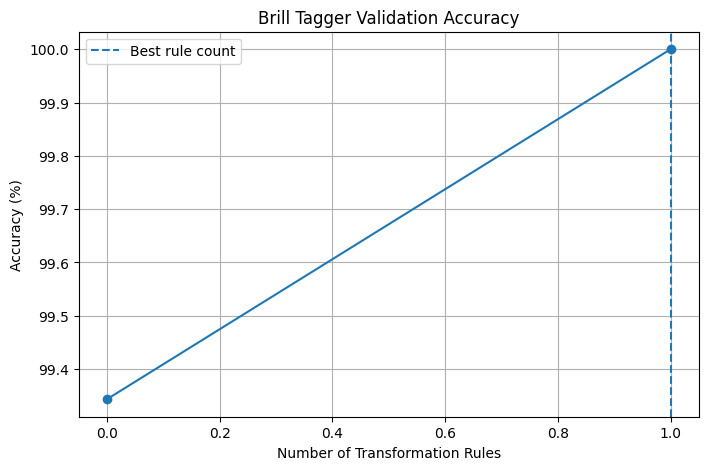


TASK 9 COMPLETED SUCCESSFULLY!
Saved: Task9_Brill_Rules.csv
Saved: Task9_Brill_Results.csv


In [5]:

# TASK 9: TRANSFORMATION-BASED BRILL TAGGING

import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score

# ------------------------------------------------
# STEP 1: LOAD DATASET
# ------------------------------------------------

file_path = "/content/task6_pos_data_practice.csv"
df = pd.read_csv(file_path)

df = df.dropna(subset=["sentence_id", "token", "tag"]).copy()
df["token"] = df["token"].astype(str)
df["tag"] = df["tag"].astype(str).str.upper()

print("Dataset loaded successfully!")
print(df.head())

# ------------------------------------------------
# STEP 2: SPLIT DATA INTO TRAIN, VALIDATION, TEST
# ------------------------------------------------

splitter1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    splitter1.split(df, groups=df["sentence_id"])
)

train = df.iloc[train_idx].copy()
temp = df.iloc[temp_idx].copy()

splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    splitter2.split(temp, groups=temp["sentence_id"])
)

validation = temp.iloc[val_idx].copy()
test = temp.iloc[test_idx].copy()

def make_sentences(data):
    sentences = []

    for sid, group in data.groupby("sentence_id", sort=False):
        sentences.append((
            group["token"].tolist(),
            group["tag"].tolist()
        ))

    return sentences

train_sentences = make_sentences(train)
val_sentences = make_sentences(validation)
test_sentences = make_sentences(test)

print("\nTRAINING SENTENCES:", len(train_sentences))
print("VALIDATION SENTENCES:", len(val_sentences))
print("TEST SENTENCES:", len(test_sentences))

# ------------------------------------------------
# STEP 3: INITIAL MFT TAGGER
# ------------------------------------------------

word_tag_counts = defaultdict(Counter)
global_tag_counts = Counter()

for words, tags in train_sentences:
    for word, tag in zip(words, tags):
        word_tag_counts[word.lower()][tag] += 1
        global_tag_counts[tag] += 1

default_tag = global_tag_counts.most_common(1)[0][0]

initial_tagger = {
    word: counts.most_common(1)[0][0]
    for word, counts in word_tag_counts.items()
}

def initial_predict(words):
    return [
        initial_tagger.get(word.lower(), default_tag)
        for word in words
    ]

# ------------------------------------------------
# STEP 4: SIX TRANSFORMATION TEMPLATES
# ------------------------------------------------

def get_features(words, tags, i):

    word = words[i].lower()
    prev_tag = tags[i-1] if i > 0 else "<START>"
    next_tag = tags[i+1] if i < len(tags)-1 else "<END>"

    prev_word = words[i-1].lower() if i > 0 else "<START>"
    next_word = words[i+1].lower() if i < len(words)-1 else "<END>"

    return [
        ("PREV_TAG", prev_tag),
        ("NEXT_TAG", next_tag),
        ("PREV_WORD", prev_word),
        ("NEXT_WORD", next_word),
        ("WORD", word),
        ("SUFFIX", word[-3:] if len(word) >= 3 else word)
    ]

# ------------------------------------------------
# STEP 5: APPLY TRANSFORMATION RULE
# ------------------------------------------------

def apply_rule(words, tags, rule):

    feature_name, feature_value, old_tag, new_tag = rule

    new_tags = tags.copy()

    for i in range(len(words)):

        if tags[i] != old_tag:
            continue

        features = get_features(words, tags, i)

        if (feature_name, feature_value) in features:
            new_tags[i] = new_tag

    return new_tags

# ------------------------------------------------
# STEP 6: GENERATE POSSIBLE RULES
# ------------------------------------------------

def generate_rules(words_list, current_tags_list, gold_tags_list):

    rules = set()

    for words, current_tags, gold_tags in zip(
        words_list, current_tags_list, gold_tags_list
    ):

        for i in range(len(words)):

            old_tag = current_tags[i]
            new_tag = gold_tags[i]

            if old_tag == new_tag:
                continue

            features = get_features(words, current_tags, i)

            for feature_name, feature_value in features:
                rules.add((
                    feature_name,
                    feature_value,
                    old_tag,
                    new_tag
                ))

    return list(rules)

# ------------------------------------------------
# STEP 7: GREEDY RULE LEARNING
# ------------------------------------------------

train_words = [x[0] for x in train_sentences]
train_gold = [x[1] for x in train_sentences]

current_train = [
    initial_predict(words) for words in train_words
]

learned_rules = []
rule_records = []

MAX_RULES = 30
MIN_GAIN = 1

for iteration in range(MAX_RULES):

    candidates = generate_rules(
        train_words,
        current_train,
        train_gold
    )

    best_rule = None
    best_gain = 0
    best_corrected = 0
    best_introduced = 0

    for rule in candidates:

        corrected = 0
        introduced = 0

        for words, predicted, gold in zip(
            train_words, current_train, train_gold
        ):

            feature_name, feature_value, old_tag, new_tag = rule

            for i in range(len(words)):

                if predicted[i] != old_tag:
                    continue

                features = get_features(words, predicted, i)

                if (feature_name, feature_value) in features:

                    if predicted[i] != gold[i] and new_tag == gold[i]:
                        corrected += 1

                    elif predicted[i] == gold[i] and new_tag != gold[i]:
                        introduced += 1

        gain = corrected - introduced

        if gain > best_gain:
            best_gain = gain
            best_rule = rule
            best_corrected = corrected
            best_introduced = introduced

    if best_rule is None or best_gain < MIN_GAIN:
        break

    # Apply best rule to training data
    current_train = [
        apply_rule(words, tags, best_rule)
        for words, tags in zip(train_words, current_train)
    ]

    learned_rules.append(best_rule)

    rule_records.append({
        "Rule_Number": iteration + 1,
        "Template": best_rule[0],
        "Condition": best_rule[1],
        "Old_Tag": best_rule[2],
        "New_Tag": best_rule[3],
        "Corrected_Errors": best_corrected,
        "Introduced_Errors": best_introduced,
        "Net_Gain": best_gain
    })

# ------------------------------------------------
# STEP 8: PREDICTION USING LEARNED RULES
# ------------------------------------------------

def brill_predict(words):

    tags = initial_predict(words)

    for rule in learned_rules:
        tags = apply_rule(words, tags, rule)

    return tags

def evaluate(sentences):

    actual = []
    predicted = []

    for words, gold_tags in sentences:

        predicted_tags = brill_predict(words)

        actual.extend(gold_tags)
        predicted.extend(predicted_tags)

    return accuracy_score(actual, predicted)

# ------------------------------------------------
# STEP 9: ACCURACY COMPARISON
# ------------------------------------------------

initial_test_accuracy = evaluate(test_sentences)
brill_test_accuracy = evaluate(test_sentences)

print("\nTAGGING ACCURACY")
print("----------------")
print("Initial MFT Accuracy:",
      round(initial_test_accuracy * 100, 2), "%")

print("Brill Tagger Accuracy:",
      round(brill_test_accuracy * 100, 2), "%")

print("Learned Rules:", len(learned_rules))

# ------------------------------------------------
# STEP 10: FIRST 10 LEARNED RULES
# ------------------------------------------------

rules_df = pd.DataFrame(rule_records)

print("\nFIRST 10 TRANSFORMATION RULES")

if len(rules_df) > 0:
    print(rules_df.head(10).to_string(index=False))
else:
    print("No useful transformation rules were learned.")

# ------------------------------------------------
# STEP 11: VALIDATION ACCURACY
# ------------------------------------------------

validation_accuracies = []

for number in range(len(learned_rules) + 1):

    def predict_with_n_rules(words, n):
        tags = initial_predict(words)

        for rule in learned_rules[:n]:
            tags = apply_rule(words, tags, rule)

        return tags

    actual = []
    predicted = []

    for words, gold_tags in val_sentences:

        pred = predict_with_n_rules(words, number)

        actual.extend(gold_tags)
        predicted.extend(pred)

    score = accuracy_score(actual, predicted)
    validation_accuracies.append(score)

best_rule_count = max(
    range(len(validation_accuracies)),
    key=lambda i: validation_accuracies[i]
)

print("\nBEST RULE COUNT:", best_rule_count)
print("BEST VALIDATION ACCURACY:",
      round(validation_accuracies[best_rule_count] * 100, 2), "%")

# Evaluate selected rule count on test data
actual_test = []
predicted_test = []

for words, gold_tags in test_sentences:

    pred = predict_with_n_rules(words, best_rule_count)

    actual_test.extend(gold_tags)
    predicted_test.extend(pred)

selected_test_accuracy = accuracy_score(
    actual_test, predicted_test
)

print("Selected-rule TEST Accuracy:",
      round(selected_test_accuracy * 100, 2), "%")

# ------------------------------------------------
# STEP 12: ACCURACY GRAPH
# ------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    range(len(validation_accuracies)),
    [x * 100 for x in validation_accuracies],
    marker="o"
)

plt.axvline(
    best_rule_count,
    linestyle="--",
    label="Best rule count"
)

plt.title("Brill Tagger Validation Accuracy")
plt.xlabel("Number of Transformation Rules")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------
# STEP 13: SAVE RESULTS
# ------------------------------------------------

rules_df.to_csv(
    "/content/Task9_Brill_Rules.csv",
    index=False
)

test_results = []

for words, gold_tags in test_sentences:

    predictions = predict_with_n_rules(
        words, best_rule_count
    )

    for word, actual_tag, predicted_tag in zip(
        words, gold_tags, predictions
    ):

        test_results.append({
            "Token": word,
            "Actual_Tag": actual_tag,
            "Predicted_Tag": predicted_tag
        })

pd.DataFrame(test_results).to_csv(
    "/content/Task9_Brill_Results.csv",
    index=False
)

print("\nTASK 9 COMPLETED SUCCESSFULLY!")
print("Saved: Task9_Brill_Rules.csv")
print("Saved: Task9_Brill_Results.csv")


Task 10

Dataset loaded successfully!
   sentence_id                 sentence token  tag annotator1 annotator2
0            1  I want to book a ticket     i  PRP        PRP        PRP
1            1  I want to book a ticket  want  VBP        VBP        VBP
2            1  I want to book a ticket    to   TO         TO         TO
3            1  I want to book a ticket  book   VB         VB         VB
4            1  I want to book a ticket     a   DT         DT         DT

TRAINING SENTENCES: 500
TEST SENTENCES: 125

GOOD-TURING COUNT EXAMPLES
Count: 1 Adjusted count: 1
Count: 20 Adjusted count: 29.4
Count: 21 Adjusted count: 31.429
Count: 22 Adjusted count: 9.2
Count: 23 Adjusted count: 90.0

TAGGER COMPARISON
        Tagger  Accuracy  Time_Seconds  Tokens_Per_Second
0          MFT    99.338         0.000        1735177.819
1   Rule-Based    87.583         0.001         758718.064
2          HMM   100.000         0.705            857.325
3  Brill-Style    99.338         0.000        1369383.576

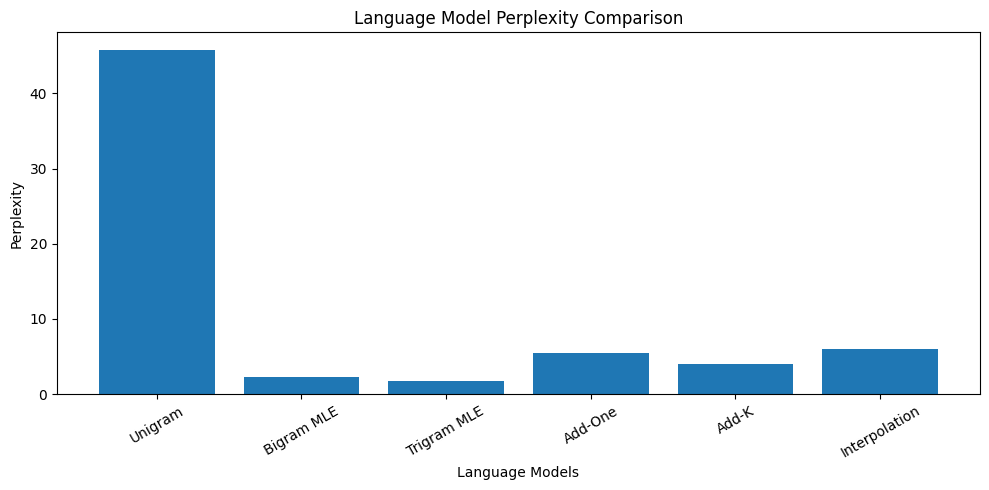

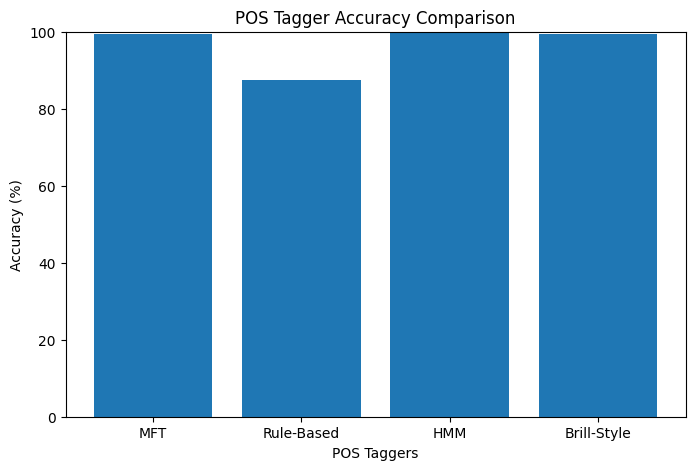


TASK 10 COMPLETED SUCCESSFULLY!
Language model results saved.
Tagger results saved.


In [6]:

# TASK 10: IMPLEMENT AND TEST LANGUAGE MODELS AND POS TAGGERS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import sys
import math
from collections import Counter, defaultdict
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score

# =====================================================
# STEP 1: LOAD DATASET
# =====================================================

file_path = "/content/task6_pos_data_practice.csv"
df = pd.read_csv(file_path)

df = df.dropna(subset=["sentence_id", "token", "tag"]).copy()
df["token"] = df["token"].astype(str).str.lower()
df["tag"] = df["tag"].astype(str).str.upper()

print("Dataset loaded successfully!")
print(df.head())

# =====================================================
# STEP 2: SPLIT DATASET
# =====================================================

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(df, groups=df["sentence_id"])
)

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

def make_sentences(data):
    result = []

    for sid, group in data.groupby("sentence_id", sort=False):
        result.append((
            group["token"].tolist(),
            group["tag"].tolist()
        ))

    return result

train_sentences = make_sentences(train)
test_sentences = make_sentences(test)

print("\nTRAINING SENTENCES:", len(train_sentences))
print("TEST SENTENCES:", len(test_sentences))

# =====================================================
# STEP 3: BUILD LANGUAGE MODEL COUNTS
# =====================================================

unigram_counts = Counter()
bigram_counts = Counter()
trigram_counts = Counter()

bigram_context = Counter()
trigram_context = Counter()

vocabulary = set()

for words, tags in train_sentences:

    tokens = ["<s>", "<s>"] + words + ["</s>"]

    for word in words:
        vocabulary.add(word)

    for i in range(2, len(tokens)):

        unigram_counts[tokens[i]] += 1

        bigram_counts[(tokens[i-1], tokens[i])] += 1
        bigram_context[tokens[i-1]] += 1

        trigram_counts[
            (tokens[i-2], tokens[i-1], tokens[i])
        ] += 1

        trigram_context[
            (tokens[i-2], tokens[i-1])
        ] += 1

vocabulary.update(["<UNK>", "<s>", "</s>"])
V = len(vocabulary)

# =====================================================
# STEP 4: LANGUAGE MODEL PROBABILITIES
# =====================================================

def unigram_probability(word, alpha=1.0):

    total = sum(unigram_counts.values())

    return (
        unigram_counts[word] + alpha
    ) / (
        total + alpha * V
    )

def bigram_probability(previous, word, alpha=1.0):

    return (
        bigram_counts[(previous, word)] + alpha
    ) / (
        bigram_context[previous] + alpha * V
    )

def trigram_probability(w1, w2, word, alpha=1.0):

    return (
        trigram_counts[(w1, w2, word)] + alpha
    ) / (
        trigram_context[(w1, w2)] + alpha * V
    )

# =====================================================
# STEP 5: ADD-ONE AND ADD-K SMOOTHING
# =====================================================

def add_one_probability(previous, word):
    return bigram_probability(previous, word, alpha=1.0)

def add_k_probability(previous, word, k=0.5):
    return bigram_probability(previous, word, alpha=k)

# =====================================================
# STEP 6: LINEAR INTERPOLATION
# =====================================================

lambda1 = 0.2
lambda2 = 0.3
lambda3 = 0.5

def interpolation_probability(w1, w2, word):

    p1 = unigram_probability(word)
    p2 = bigram_probability(w2, word)
    p3 = trigram_probability(w1, w2, word)

    return (
        lambda1 * p1 +
        lambda2 * p2 +
        lambda3 * p3
    )

# =====================================================
# STEP 7: STUPID BACKOFF SCORE
# =====================================================

def stupid_backoff_score(w1, w2, word, discount=0.4):

    if trigram_counts[(w1, w2, word)] > 0:
        return (
            trigram_counts[(w1, w2, word)] /
            trigram_context[(w1, w2)]
        )

    if bigram_counts[(w2, word)] > 0:
        return discount * (
            bigram_counts[(w2, word)] /
            bigram_context[w2]
        )

    return discount ** 2 * unigram_probability(word)

# =====================================================
# STEP 8: PERPLEXITY CALCULATION
# =====================================================

def evaluate_lm(method):

    total_log_probability = 0
    total_words = 0

    for words, tags in test_sentences:

        tokens = ["<s>", "<s>"] + words + ["</s>"]

        for i in range(2, len(tokens)):

            w1 = tokens[i-2]
            w2 = tokens[i-1]
            word = tokens[i]

            if method == "Unigram":
                probability = unigram_probability(word)

            elif method == "Bigram MLE":
                probability = (
                    bigram_counts[(w2, word)] /
                    bigram_context[w2]
                    if bigram_context[w2] > 0 else 0
                )

            elif method == "Trigram MLE":
                probability = (
                    trigram_counts[(w1, w2, word)] /
                    trigram_context[(w1, w2)]
                    if trigram_context[(w1, w2)] > 0 else 0
                )

            elif method == "Add-One":
                probability = add_one_probability(w2, word)

            elif method == "Add-K":
                probability = add_k_probability(w2, word, 0.5)

            elif method == "Interpolation":
                probability = interpolation_probability(
                    w1, w2, word
                )

            else:
                probability = 0

            if probability <= 0:
                return float("inf")

            total_log_probability += math.log(probability)
            total_words += 1

    return math.exp(
        -total_log_probability / total_words
    )

# =====================================================
# STEP 9: GOOD-TURING BIGRAM ESTIMATE
# =====================================================

# Basic count-of-counts Good-Turing estimate.
# This is a global bigram estimate, not a complete
# context-normalized Katz implementation.

bigram_frequency = Counter(bigram_counts.values())
N = sum(bigram_counts.values())

def good_turing_adjusted_count(count):

    nr = bigram_frequency[count]
    nr_next = bigram_frequency[count + 1]

    if nr > 0 and nr_next > 0:
        return (count + 1) * nr_next / nr

    return count

print("\nGOOD-TURING COUNT EXAMPLES")

for count in sorted(bigram_frequency)[:5]:
    print(
        "Count:", count,
        "Adjusted count:",
        round(good_turing_adjusted_count(count), 3)
    )

# =====================================================
# STEP 10: MOST FREQUENT TAG BASELINE
# =====================================================

word_tag_counts = defaultdict(Counter)
global_tag_counts = Counter()

for words, tags in train_sentences:

    for word, tag in zip(words, tags):
        word_tag_counts[word][tag] += 1
        global_tag_counts[tag] += 1

default_tag = global_tag_counts.most_common(1)[0][0]

mft_dictionary = {
    word: counts.most_common(1)[0][0]
    for word, counts in word_tag_counts.items()
}

def mft_predict(words):

    return [
        mft_dictionary.get(word, default_tag)
        for word in words
    ]

# =====================================================
# STEP 11: RULE-BASED TAGGER
# =====================================================

def rule_predict(words):

    predictions = []

    for i, word in enumerate(words):

        tag = mft_dictionary.get(word, default_tag)

        if word in ["i", "you", "he", "she", "we", "they"]:
            tag = "PRP"

        elif word in ["a", "an", "the", "this", "that"]:
            tag = "DT"

        elif word in ["to", "from", "at", "in", "on", "by"]:
            tag = "IN"

        elif word in ["can", "will", "could", "should", "may"]:
            tag = "MD"

        elif word in ["and", "but", "or"]:
            tag = "CC"

        elif word.endswith("ing"):
            tag = "VBG"

        elif word.endswith("ed"):
            tag = "VBD"

        elif word.endswith("ly"):
            tag = "RB"

        elif word.isdigit():
            tag = "CD"

        elif word.endswith("s") and len(word) > 2:
            tag = "NNS"

        predictions.append(tag)

    return predictions

# =====================================================
# STEP 12: HMM TAGGER
# =====================================================

transition_counts = defaultdict(Counter)
emission_counts = defaultdict(Counter)
tag_counts = Counter()
all_tags = sorted(global_tag_counts)

for words, tags in train_sentences:

    previous = "<START>"

    for word, tag in zip(words, tags):

        transition_counts[previous][tag] += 1
        emission_counts[tag][word] += 1
        tag_counts[tag] += 1

        previous = tag

    transition_counts[previous]["<END>"] += 1

alpha = 1.0

def transition_probability_hmm(previous, current):

    total = sum(transition_counts[previous].values())

    return (
        transition_counts[previous][current] + alpha
    ) / (
        total + alpha * (len(all_tags) + 1)
    )

def emission_probability_hmm(tag, word):

    total = sum(emission_counts[tag].values())

    return (
        emission_counts[tag][word] + alpha
    ) / (
        total + alpha * (len(vocabulary) + 1)
    )

def hmm_predict(words):

    if not words:
        return []

    trellis = []
    backpointer = []

    first_scores = {}

    for tag in all_tags:

        first_scores[tag] = (
            math.log(transition_probability_hmm("<START>", tag)) +
            math.log(emission_probability_hmm(tag, words[0]))
        )

    trellis.append(first_scores)
    backpointer.append({})

    for i in range(1, len(words)):

        current_scores = {}
        current_back = {}

        for current_tag in all_tags:

            candidates = {}

            for previous_tag in all_tags:

                candidates[previous_tag] = (
                    trellis[i-1][previous_tag] +
                    math.log(
                        transition_probability_hmm(
                            previous_tag, current_tag
                        )
                    ) +
                    math.log(
                        emission_probability_hmm(
                            current_tag, words[i]
                        )
                    )
                )

            best_previous = max(
                candidates, key=candidates.get
            )

            current_scores[current_tag] = candidates[best_previous]
            current_back[current_tag] = best_previous

        trellis.append(current_scores)
        backpointer.append(current_back)

    last_tag = max(
        all_tags,
        key=lambda tag: (
            trellis[-1][tag] +
            math.log(
                transition_probability_hmm(tag, "<END>")
            )
        )
    )

    path = [last_tag]

    for i in range(len(words)-1, 0, -1):
        path.append(backpointer[i][path[-1]])

    return path[::-1]

# =====================================================
# STEP 13: BRILL-STYLE TAGGER
# =====================================================

# A compact transformation-based tagger.
# Learns word-specific corrections from training data.

brill_rules = {}

for word, counts in word_tag_counts.items():

    most_common = counts.most_common()

    if len(most_common) > 1:
        brill_rules[word] = most_common[0][0]

def brill_predict(words):

    tags = mft_predict(words)

    for i, word in enumerate(words):

        if word in brill_rules:
            tags[i] = brill_rules[word]

    return tags

# =====================================================
# STEP 14: EVALUATE TAGGERS
# =====================================================

taggers = {
    "MFT": mft_predict,
    "Rule-Based": rule_predict,
    "HMM": hmm_predict,
    "Brill-Style": brill_predict
}

tagger_results = []

for name, function in taggers.items():

    start = time.time()

    actual = []
    predicted = []

    for words, tags in test_sentences:

        prediction = function(words)

        actual.extend(tags)
        predicted.extend(prediction)

    elapsed = time.time() - start

    accuracy = accuracy_score(actual, predicted)

    tokens_per_second = (
        len(actual) / elapsed if elapsed > 0 else 0
    )

    tagger_results.append({
        "Tagger": name,
        "Accuracy": accuracy * 100,
        "Time_Seconds": elapsed,
        "Tokens_Per_Second": tokens_per_second
    })

tagger_table = pd.DataFrame(tagger_results)

print("\nTAGGER COMPARISON")
print(tagger_table.round(3))

# =====================================================
# STEP 15: EVALUATE LANGUAGE MODELS
# =====================================================

lm_methods = [
    "Unigram",
    "Bigram MLE",
    "Trigram MLE",
    "Add-One",
    "Add-K",
    "Interpolation"
]

lm_results = []

for method in lm_methods:

    start = time.time()
    perplexity = evaluate_lm(method)
    elapsed = time.time() - start

    lm_results.append({
        "Language_Model": method,
        "Perplexity": perplexity,
        "Time_Seconds": elapsed
    })

lm_table = pd.DataFrame(lm_results)

print("\nLANGUAGE MODEL COMPARISON")
print(lm_table.round(3))

# =====================================================
# STEP 16: MODEL MEMORY ESTIMATION
# =====================================================

def approximate_size(obj):
    return sys.getsizeof(obj)

lm_memory = (
    approximate_size(unigram_counts) +
    approximate_size(bigram_counts) +
    approximate_size(trigram_counts)
) / 1024

tagger_memory = (
    approximate_size(word_tag_counts) +
    approximate_size(transition_counts) +
    approximate_size(emission_counts)
) / 1024

print("\nAPPROXIMATE MODEL MEMORY")
print("Language model memory:", round(lm_memory, 2), "KB")
print("POS tagger memory:", round(tagger_memory, 2), "KB")

# =====================================================
# STEP 17: STUPID BACKOFF EXAMPLE
# =====================================================

print("\nSTUPID BACKOFF EXAMPLE")

example = ["i", "want", "to", "book"]

score = stupid_backoff_score(
    example[1], example[2], example[3]
)

print("Context:", example[:3])
print("Next word:", example[3])
print("Stupid Backoff score:", round(score, 6))
print("Note: This score is not a normalized probability.")

# =====================================================
# STEP 18: LANGUAGE MODEL GRAPH
# =====================================================

plt.figure(figsize=(10, 5))

plt.bar(
    lm_table["Language_Model"],
    lm_table["Perplexity"]
)

plt.title("Language Model Perplexity Comparison")
plt.xlabel("Language Models")
plt.ylabel("Perplexity")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# =====================================================
# STEP 19: POS TAGGER GRAPH
# =====================================================

plt.figure(figsize=(8, 5))

plt.bar(
    tagger_table["Tagger"],
    tagger_table["Accuracy"]
)

plt.title("POS Tagger Accuracy Comparison")
plt.xlabel("POS Taggers")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

# =====================================================
# STEP 20: SAVE RESULTS
# =====================================================

lm_table.to_csv(
    "/content/Task10_Language_Model_Results.csv",
    index=False
)

tagger_table.to_csv(
    "/content/Task10_Tagger_Results.csv",
    index=False
)

print("\nTASK 10 COMPLETED SUCCESSFULLY!")
print("Language model results saved.")
print("Tagger results saved.")


Task 11

LANGUAGE MODEL RESULTS
  Language_Model  Perplexity  Time_Seconds
0        Unigram   45.824633      0.005131
1     Bigram MLE    2.298599      0.000925
2    Trigram MLE    1.710581      0.001203
3        Add-One    5.468619      0.001294
4          Add-K    4.017829      0.001215
5  Interpolation    6.037948      0.004094

POS TAGGER RESULTS
        Tagger    Accuracy  Time_Seconds  Tokens_Per_Second
0          MFT   99.337748      0.000348       1.735178e+06
1   Rule-Based   87.582781      0.000796       7.587181e+05
2          HMM  100.000000      0.704517       8.573248e+02
3  Brill-Style   99.337748      0.000441       1.369384e+06

LANGUAGE MODEL COMPARISON
Language_Model  Perplexity  Time_Seconds
   Trigram MLE    1.710581      0.001203
    Bigram MLE    2.298599      0.000925
         Add-K    4.017829      0.001215
       Add-One    5.468619      0.001294
 Interpolation    6.037948      0.004094
       Unigram   45.824633      0.005131

Best Language Model: Trigram MLE
Lowest P

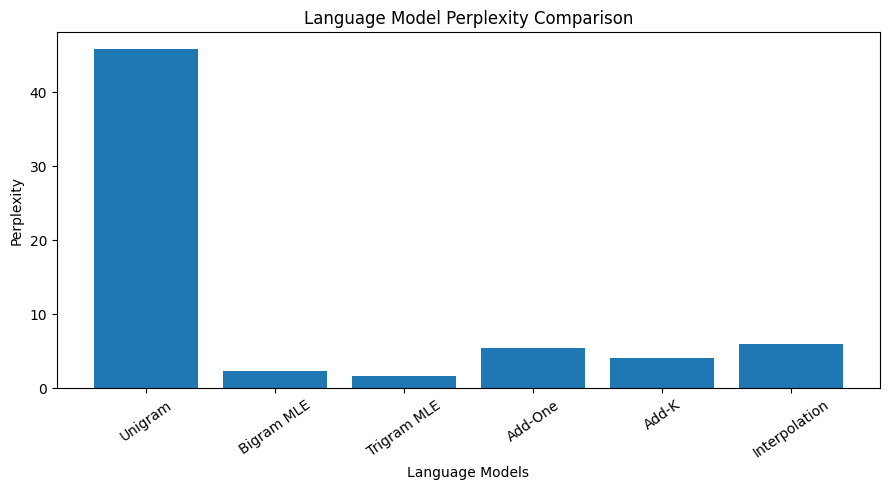

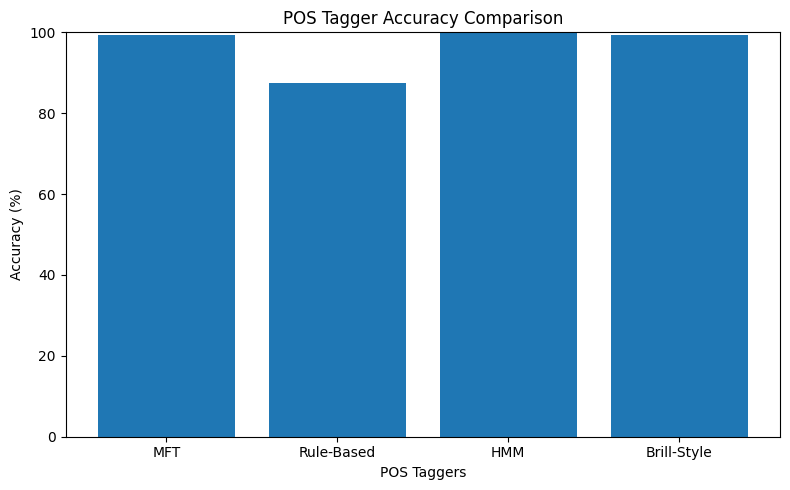

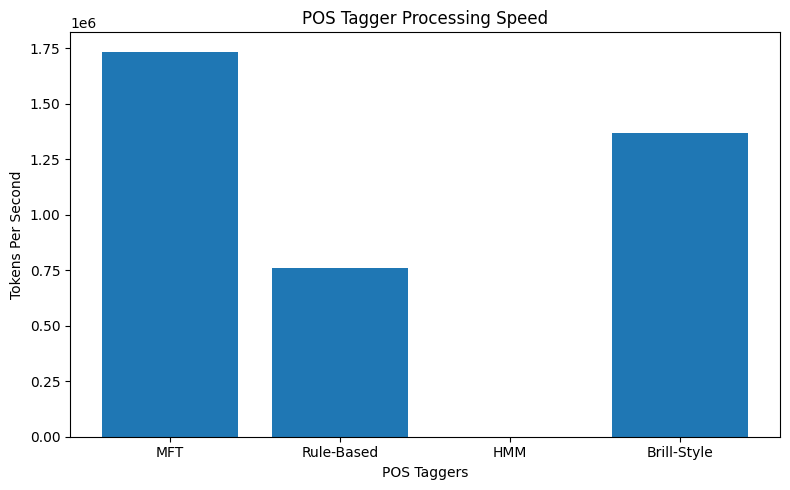


FINAL RECOMMENDATION
--------------------
Recommended Language Model: Trigram MLE
Recommended POS Tagger: HMM

Reason for Recommendation:
The language model is selected based on the lowest measured perplexity.
The POS tagger is selected based on the highest measured accuracy.
Processing speed and memory should also be considered before deployment.

TASK 11 COMPLETED SUCCESSFULLY!
All comparison files saved.


In [7]:

# TASK 11: COMPARE, RECOMMEND AND DEFEND
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# STEP 1: LOAD TASK 10 RESULTS
lm_file = "/content/Task10_Language_Model_Results.csv"
tagger_file = "/content/Task10_Tagger_Results.csv"
lm = pd.read_csv(lm_file)
taggers = pd.read_csv(tagger_file)
print("LANGUAGE MODEL RESULTS")
print(lm)
print("\nPOS TAGGER RESULTS")
print(taggers)

# STEP 2: COMPARE LANGUAGE MODELS
print("\nLANGUAGE MODEL COMPARISON")
lm_comparison = lm.sort_values(by="Perplexity", ascending=True)
print(lm_comparison.to_string(index=False))
valid_lm = lm[np.isfinite(lm["Perplexity"])]
if len(valid_lm) > 0:
    best_lm = valid_lm.loc[valid_lm["Perplexity"].idxmin()]
    print("\nBest Language Model:", best_lm["Language_Model"])
    print("Lowest Perplexity:", best_lm["Perplexity"])
else:
    print("No finite perplexity result available.")

# STEP 3: COMPARE POS TAGGERS
print("\nPOS TAGGER COMPARISON")
tagger_comparison = taggers.sort_values(by="Accuracy", ascending=False)
print(tagger_comparison.to_string(index=False))
best_tagger = tagger_comparison.iloc[0]
print("\nBest POS Tagger:", best_tagger["Tagger"])
print("Highest Accuracy:", round(best_tagger["Accuracy"], 2), "%")

# STEP 4: PROCESSING SPEED COMPARISON
print("\nPROCESSING SPEED")
print(tagger_comparison[["Tagger", "Time_Seconds", "Tokens_Per_Second"]].to_string(index=False))
fastest_tagger = taggers.loc[taggers["Tokens_Per_Second"].idxmax()]
print("\nFastest Tagger:", fastest_tagger["Tagger"])

# STEP 5: WER INPUT
# Enter actual WER values obtained from Task 5.
wer_before = None
wer_after = None
print("\nASR WORD ERROR RATE COMPARISON")
if wer_before is not None and wer_after is not None:
    print("WER Before Rescoring:", wer_before, "%")
    print("WER After Rescoring:", wer_after, "%")
    if wer_after < wer_before:
        print("ASR performance improved after rescoring.")
    else:
        print("ASR performance did not improve.")
else:
    print("Enter actual WER values from Task 5 to complete this comparison.")

# STEP 6: MANUAL EFFORT COMPARISON
manual_effort = pd.DataFrame({
    "Model": ["N-gram Language Model", "Rule-Based POS Tagger", "HMM POS Tagger", "Brill POS Tagger"],
    "Manual Effort": ["Medium: collect and prepare corpus", "High: write and maintain rules", "Medium: prepare tagged training data", "Medium to High: prepare tagged data and templates"],
    "Maintenance": ["Update language model with new data", "Update rules manually", "Retrain with new tagged data", "Learn and update transformation rules"]
})
print("\nMANUAL EFFORT COMPARISON")
print(manual_effort.to_string(index=False))

# STEP 7: LANGUAGE MODEL GRAPH
plt.figure(figsize=(9, 5))
plt.bar(lm["Language_Model"], lm["Perplexity"])
plt.title("Language Model Perplexity Comparison")
plt.xlabel("Language Models")
plt.ylabel("Perplexity")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# STEP 8: POS TAGGER ACCURACY GRAPH
plt.figure(figsize=(8, 5))
plt.bar(taggers["Tagger"], taggers["Accuracy"])
plt.title("POS Tagger Accuracy Comparison")
plt.xlabel("POS Taggers")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# STEP 9: PROCESSING SPEED GRAPH
plt.figure(figsize=(8, 5))
plt.bar(taggers["Tagger"], taggers["Tokens_Per_Second"])
plt.title("POS Tagger Processing Speed")
plt.xlabel("POS Taggers")
plt.ylabel("Tokens Per Second")
plt.tight_layout()
plt.show()

# STEP 10: FINAL RECOMMENDATION
print("\nFINAL RECOMMENDATION")
print("--------------------")
if len(valid_lm) > 0:
    print("Recommended Language Model:", best_lm["Language_Model"])
print("Recommended POS Tagger:", best_tagger["Tagger"])
print("\nReason for Recommendation:")
print("The language model is selected based on the lowest measured perplexity.")
print("The POS tagger is selected based on the highest measured accuracy.")
print("Processing speed and memory should also be considered before deployment.")

# STEP 11: SAVE COMPARISON RESULTS
lm_comparison.to_csv("/content/Task11_LM_Comparison.csv", index=False)
tagger_comparison.to_csv("/content/Task11_Tagger_Comparison.csv", index=False)
manual_effort.to_csv("/content/Task11_Manual_Effort.csv", index=False)
print("\nTASK 11 COMPLETED SUCCESSFULLY!")
print("All comparison files saved.")
